# DeliveryIQ — Notebook 03: Model Training, Evaluation and Honest Conclusions

**Project:** DeliveryIQ — Intelligent Shipment Analytics & Delay Prediction (Fundamentals of Data Science)
**Notebook:** `notebooks/03_model_training.ipynb`  |  **Data:** Olist Brazilian E-Commerce Public Dataset (2016–2018, historical)

## What this notebook does
It rebuilds, step by step and with the *same code the app uses* (`src/train_model.py`, `src/prediction.py`), the delay-risk model that powers
the **Delay Prediction** page, evaluates it honestly, and explains what it can and cannot do.

1. Frame the problem and define the target (`is_late`) and its class imbalance.
2. Choose predictors: a **purchase-time allow-list** versus a **leakage list**, with a leakage experiment that shows why the line matters.
3. Split the data **chronologically** (train → validation → test) and show why the late rate is not stationary.
4. Show the preprocessing pipeline (imputation, scaling, one-hot) that is shared by training and the app.
5. Train a dummy baseline, **logistic regression**, **random forest** and **histogram gradient boosting**, and reconcile every number with `models/model_metrics.json`.
6. Evaluate with the metrics that suit a rare outcome (PR-AUC, recall/precision, ROC-AUC, Brier, calibration) and explain why accuracy misleads.
7. Choose the decision threshold and the Low / Moderate / High risk bands on **validation**, then check them on **test**.
8. Permutation importance and coefficients: predictive associations, **not causes**.
9. Select the final model, diagnose why test performance is much weaker than validation, and state the conclusion plainly.
10. Load the saved bundle and score three real test-window orders with `prediction.predict_risk`.

## Headline, stated up front
The selected model is a **logistic regression** with a **modest but real** ranking signal. On the untouched test window it reaches ROC-AUC 0.617 and PR-AUC 0.073
against a no-skill PR-AUC of 0.048. That is **far weaker than on the validation window** (ROC-AUC 0.781, PR-AUC 0.140), where the model was tuned. The late rate moved
between windows (train 8.0%, validation 4.2%, test 4.8%), the Moderate and High risk bands are barely separated on test, and the probabilities are not better calibrated
than quoting the base rate. **The model is a rough triage aid, not an accurate or reliable predictor**, and it says nothing about causes or about today's logistics performance.

## How to run
From the project root, with the project virtual environment (the processed data and the saved model must exist; if not, run the two commands in the comments):

```bash
# .venv/bin/python -m src.preprocessing     # only if data/processed/*.parquet are missing
# .venv/bin/python -m src.train_model       # only if models/ is missing (NOT needed to run this notebook's training cells)
.venv/bin/jupyter lab notebooks/03_model_training.ipynb
```
The notebook finds the project root by itself. It trains the models itself (about 1.5 minutes in total; the slow random-forest / boosting grids are not re-run, see section 5)
and saves its figures as PNG files `30_…` to `39_…` in `reports/figures/`.

**Conventions.** Rates always come with their sample size `n`. "Associated with" never means "caused by". Validation numbers are labelled *tuned / in-sample* wherever the
validation window influenced a choice; only the **test window** is an out-of-sample estimate. No fitting, tuning, calibration, threshold, band or model-choice step uses the test window; it is used only for evaluation and for clearly labelled diagnostics (the leakage and random-split demonstrations, bootstrap intervals, permutation importance and the drift analysis), none of which feeds back into a decision.

In [1]:
import sys, json, time, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

# Resolve the project root whether the notebook is run from notebooks/ or from the root.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "src" / "config.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the DeliveryIQ project folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config, prediction as pred, train_model as tm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

P = config.PALETTE
MODEL_COLORS = {"dummy_prior": P["slate_light"], "logistic_regression": P["blue"],
                "random_forest": "#0891B2", "hist_gradient_boosting": "#7C3AED"}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": P["slate_light"], "axes.labelcolor": P["slate"],
    "axes.titlecolor": P["navy"], "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": P["border"], "grid.linewidth": 0.7,
    "axes.axisbelow": True, "xtick.color": P["slate"], "ytick.color": P["slate"],
    "font.size": 10, "legend.frameon": False,
})
FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
T0 = time.time()


def save_show(fig, name: str) -> None:
    """Save a figure as PNG under reports/figures/ (for GitHub) and display it inline."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def wrap(text: str, width: int = 118) -> None:
    print(textwrap.fill(str(text), width=width))


def pct(x: float, d: int = 1) -> str:
    return f"{100 * x:.{d}f}%"


# Numbers quoted in the Markdown are registered here as formatted strings; the build script checks
# that every one of them appears in the narrative, so text and computed values cannot drift apart.
QUOTED: dict[str, str] = {}

saved = json.load(open(config.MODEL_METRICS_PATH))
print(f"Project root : {ROOT}")
print(f"Saved model metrics generated at {saved['generated_at']}  (scikit-learn {saved['library_versions']['scikit-learn']})")
print(f"Selected model on disk       : {saved['selected_model']['name']}")

Project root : /Users/keertika/Desktop/fods
Saved model metrics generated at 2026-10-22T22:19:54+00:00  (scikit-learn 1.9.1)
Selected model on disk       : logistic_regression


## 1. Problem framing and target definition

**Question.** *At the moment a customer places an order, how likely is it that the order will arrive later than the delivery date promised at checkout?*

**Use case.** A seller-support or operations team could review the highest-risk new orders first. This is a **triage / ranking** task: a useful model puts truly late
orders higher in the list than on-time ones. Because the outcome is rare, "how many late orders are in the top of the list" matters more than overall accuracy.

**Target.** `is_late = 1` when the order was delivered **after the estimated delivery calendar date**, else 0.

* The rule is **calendar-date based**: `delivery_delay_days = delivered date − estimated date` (both truncated to the day) and `is_late = delay > 0`. Arriving at any time on the promised day is on time.
* Only **delivered** orders with all required timestamps are labelled (the analysis set). Cancelled, unavailable and still-in-transit orders have no label; they are never treated as on time.
* A customer's *promised* date is the Olist estimate shown at checkout, so "late" means "later than promised", not "slow in absolute terms".

In [2]:
df = tm.load_training_frame()          # delivered, labelled orders, sorted by purchase time
y_all = df[tm.TARGET]
n_all, n_late_all = len(df), int(y_all.sum())
print(f"Analysis set: {n_all:,} delivered orders, purchases {df['order_purchase_timestamp'].min():%Y-%m-%d} .. "
      f"{df['order_purchase_timestamp'].max():%Y-%m-%d}")
print(f"Late orders : {n_late_all:,}  ({pct(y_all.mean(), 2)})   on time / early: {n_all - n_late_all:,}  ({pct(1 - y_all.mean(), 2)})")
print(f"Class ratio : {(n_all - n_late_all) / n_late_all:.1f} on-time orders for every late order")

est, dlv = df["order_estimated_delivery_date"], df["order_delivered_customer_date"]
ts_late = dlv > est                                  # naive: compare full timestamps
cal_late = df["delivery_delay_days"] > 0             # project rule: calendar dates
same_day = (dlv.dt.normalize() == est.dt.normalize()) & ts_late
rule = pd.DataFrame({
    "rule": ["calendar-date rule (used: delivered date > estimated date)", "timestamp rule (delivered time > estimated midnight)"],
    "late orders": [int(cal_late.sum()), int(ts_late.sum())],
    "late rate": [cal_late.mean(), ts_late.mean()],
})
display(rule)
print(f"Orders that arrive during the promised calendar day but after its midnight timestamp: {int(same_day.sum()):,} "
      f"(= {int(ts_late.sum()) - int(cal_late.sum()):,} difference between the two rules)")
assert int(same_day.sum()) == int(ts_late.sum()) - int(cal_late.sum())
assert (cal_late.astype(int) == y_all).all()
QUOTED["n_all"] = f"{n_all:,}"
QUOTED["n_late_all"] = f"{n_late_all:,}"
QUOTED["late_rate_all"] = pct(y_all.mean(), 2)
QUOTED["class_ratio"] = f"{(n_all - n_late_all) / n_late_all:.1f}"
QUOTED["n_same_day"] = f"{int(same_day.sum()):,}"
QUOTED["ts_late_rate"] = pct(ts_late.mean(), 2)

Analysis set: 96,470 delivered orders, purchases 2016-09-15 .. 2018-08-29
Late orders : 6,534  (6.77%)   on time / early: 89,936  (93.23%)
Class ratio : 13.8 on-time orders for every late order


,rule,late orders,late rate
0,calendar-date rule (used: delivered date > estimated date),6534,0.0677
1,timestamp rule (delivered time > estimated midnight),7826,0.0811


Orders that arrive during the promised calendar day but after its midnight timestamp: 1,292 (= 1,292 difference between the two rules)


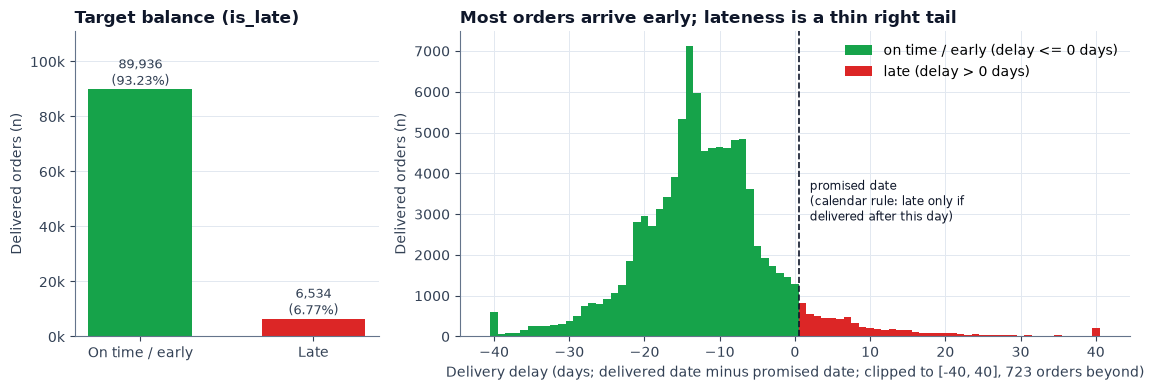

In [3]:
delay = df["delivery_delay_days"].astype(float)
lo, hi = -40, 40
beyond = int(((delay < lo) | (delay > hi)).sum())
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={"width_ratios": [1, 2.2]})

ax = axes[0]
counts = [n_all - n_late_all, n_late_all]
bars = ax.bar(["On time / early", "Late"], counts, color=[P["green"], P["red"]], width=0.6)
for b, v in zip(bars, counts):
    ax.annotate(f"{v:,}\n({v / n_all:.2%})", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=9, color=P["slate"])
ax.set_ylim(0, n_all * 1.15)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_ylabel("Delivered orders (n)"); ax.set_title("Target balance (is_late)")
ax.grid(axis="x", visible=False)

ax = axes[1]
vals = delay.clip(lo, hi)
edges = np.arange(lo - 0.5, hi + 1.5, 1)
neg = vals[vals <= 0]; posv = vals[vals > 0]
ax.hist(neg, bins=edges, color=P["green"], label="on time / early (delay <= 0 days)")
ax.hist(posv, bins=edges, color=P["red"], label="late (delay > 0 days)")
ax.axvline(0.5, color=P["navy"], lw=1.2, ls="--")
ax.annotate("promised date\n(calendar rule: late only if\ndelivered after this day)", (0.5, ax.get_ylim()[1] * 0.38), xytext=(8, 0),
            textcoords="offset points", fontsize=8.5, color=P["navy"])
ax.set_xlabel(f"Delivery delay (days; delivered date minus promised date; clipped to [{lo}, {hi}], {beyond:,} orders beyond)")
ax.set_ylabel("Delivered orders (n)"); ax.set_title("Most orders arrive early; lateness is a thin right tail")
ax.legend(loc="upper right")
save_show(fig, "30_target_balance_and_delay")

**Interpretation.**

* The analysis set holds **96,470** delivered orders; **6,534** are late, a prevalence of **6.77%**, i.e. **13.8** on-time orders for every late one.
* The calendar-date rule matters: comparing full timestamps instead would label **8.11%** of orders late. The difference is exactly **1,292** orders that arrived on the promised
  day but after its midnight timestamp. Counting those as late would punish deliveries that kept the promise.
* The delay histogram shows why the target is imbalanced: most orders arrive days or weeks *before* the promised date, and lateness is a thin right tail.
* **Consequence for evaluation.** A model that never predicts "late" is right for about 93% of these orders. Accuracy therefore cannot be the headline metric; the no-skill
  value of PR-AUC equals the prevalence, and every later comparison is made against that reference (see sections 6 and 7).

## 2. Predictive feature selection and the leakage list

A delay-risk model must be usable **at purchase time**. `src/config.py` therefore partitions every processed column into exactly one of four groups, and the training script
refuses to run if a model input is outside the allow-list (this is also checked by unit tests and recorded in the model's `leakage_audit`):

1. **Purchase-time allow-list** (`PURCHASE_TIME_FEATURES`): order size, price, freight, weight and volume aggregates, the checkout promise `estimated_delivery_days`, purchase month / weekday / quarter,
   customer state, seller state, representative product category and `same_state`.
2. **Known at purchase but left out**: high-cardinality cities and `state_pair`, secondary counts and data-quality flags.
3. **Leakage / outcome** (`LEAKAGE_COLUMNS`): final status, post-purchase timestamps, durations and delays, processing time, review score, eligibility bookkeeping — they either *are* the outcome or only exist after it.
4. **Non-feature**: keys, raw timestamps used for the split, and time-drift proxies (year, date, year-month).

In [4]:
def group_of(col: str) -> str:
    if col in config.LEAKAGE_COLUMNS:
        return "3 Leakage / outcome (never a feature)"
    if col in config.PURCHASE_TIME_FEATURES:
        return "1 Purchase-time allow-list"
    if col in config.PURCHASE_TIME_UNUSED:
        return "2 Known at purchase, left out of the allow-list"
    if col in config.NON_FEATURE_COLUMNS:
        return "4 Non-feature (key / split key / time-drift proxy)"
    return "? unclassified"

col_table = pd.DataFrame({"column": df.columns, "group": [group_of(c) for c in df.columns]}).sort_values(["group", "column"])
assert not (col_table["group"] == "? unclassified").any(), "a processed column is not classified"
summary = (col_table.groupby("group")["column"].agg(n="size", columns=lambda s: ", ".join(s))
           .reset_index())
display(summary)
print(f"Every one of the {len(df.columns)} processed columns is in exactly one group: "
      f"{col_table['column'].is_unique and not (col_table['group'] == '? unclassified').any()}")

,group,n,columns
0,1 Purchase-time allow-list,18,"customer_state, estimated_delivery_days, freight_ratio, max_product_height_cm, max_product_length_cm, max_product_width_cm, n_items, n_s..."
1,"2 Known at purchase, left out of the allow-list",7,"category_missing, customer_city, n_categories, n_products, seller_city, state_pair, weight_missing"
2,3 Leakage / outcome (never a feature),15,"analysis_eligible, approval_days, approval_missing, carrier_date_invalid, carrier_to_customer_days, delivery_delay_days, delivery_durati..."
3,4 Non-feature (key / split key / time-drift proxy),6,"order_estimated_delivery_date, order_id, order_purchase_timestamp, purchase_date, purchase_year, purchase_year_month"


Every one of the 46 processed columns is in exactly one group: True


In [5]:
# Feature selection exactly as the training script does it (redundancy screen + calendar-month rule).
parts = tm.chronological_split(df)
tr, va, te = parts["train"], parts["validation"], parts["test"]
t = time.time()
numeric, categorical, dropped = tm.select_features(parts, quick=False)
cols = numeric + categorical
print(f"select_features finished in {time.time() - t:.0f}s")
print(f"\nModel inputs ({len(cols)}): {len(numeric)} numeric + {len(categorical)} categorical")
print("  numeric    :", ", ".join(numeric))
print("  categorical:", ", ".join(categorical))
assert cols == saved["features"]["numeric"] + saved["features"]["categorical"], "feature list differs from the saved model"
print("-> identical to the feature list stored with the saved model: True")

drop_df = pd.DataFrame({"candidate": list(dropped), "why it is not a model input": list(dropped.values())})
display(drop_df)

select_features finished in 25s

Model inputs (16): 12 numeric + 4 categorical
  numeric    : n_items, n_sellers, total_price, total_freight, freight_ratio, total_weight_g, total_volume_cm3, max_product_length_cm, max_product_height_cm, max_product_width_cm, estimated_delivery_days, purchase_dow
  categorical: customer_state, seller_state, product_category, same_state
-> identical to the feature list stored with the saved model: True


,candidate,why it is not a model input
0,customer_city,"high cardinality (3,694 distinct values in 64,053 training orders, median 2 orders each); state captures the coarse geography"
1,seller_city,"high cardinality (470 distinct values in 64,053 training orders, median 8 orders each); state captures the coarse geography"
2,state_pair,high-cardinality interaction of seller_state x customer_state; the two states plus same_state already carry it
3,n_products,secondary order-size aggregate overlapping n_items (Spearman rho = 0.55 on the training window); kept for analytics only to limit redund...
4,n_categories,secondary order-size aggregate overlapping n_items (Spearman rho = 0.13 on the training window); kept for analytics only to limit redund...
5,category_missing,covered by the 'unknown' product_category level
6,weight_missing,covered by the median imputer's missing-value indicator on the weight / dimension columns
7,purchase_date,excluded by design: raw date is a time-drift proxy; calendar effects enter only through day-of-week
8,purchase_year,excluded by design: a year column only identifies the period (time-drift proxy) and can never generalise to unseen years
9,purchase_year_month,excluded by design: a month identifier is a time-drift proxy


### Leakage experiment — a demonstration, not a model

To make the danger concrete, the next cell trains the **same** logistic regression on the **same** training window but adds outcome-side columns to the allow-list.
These columns do not exist when a customer clicks "buy", so **none of these variants can ever be deployed**. They are shown only to demonstrate how leakage inflates scores and
why the honest score must never be compared with them.

,validation ROC-AUC,validation PR-AUC,test ROC-AUC,test PR-AUC
variant,,,,
Honest: purchase-time allow-list only,0.7774,0.1385,0.6189,0.0793
LEAK: + processing_days (seller hand-over time),0.8366,0.2040,0.8066,0.1858
LEAK: + carrier_to_customer_days,0.9728,0.8810,0.8937,0.6039
LEAK: + delivery_duration_days (purchase -> delivery),0.9999,0.9986,0.9997,0.9939


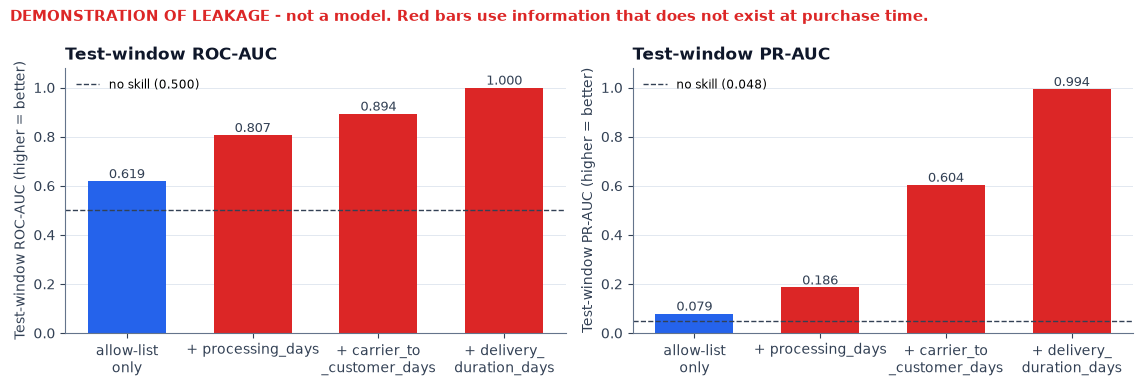

In [6]:
# DEMONSTRATION OF LEAKAGE -- NOT A MODEL.  Same pipeline and logistic regression as the real model,
# but with one or more outcome-side columns added to the allow-list.  These columns do not exist at purchase time.
variants = {
    "Honest: purchase-time allow-list only": [],
    "LEAK: + processing_days (seller hand-over time)": ["processing_days"],
    "LEAK: + carrier_to_customer_days": ["carrier_to_customer_days"],
    "LEAK: + delivery_duration_days (purchase -> delivery)": ["delivery_duration_days"],
}
rows = []
for label, extra in variants.items():
    ncols = numeric + extra
    pipe = tm.build_pipeline(LogisticRegression(max_iter=3000, C=1.0, random_state=config.RANDOM_STATE), ncols, categorical, scale=True)
    pipe.fit(tr[ncols + categorical], tr[tm.TARGET])
    row = {"variant": label}
    for wname, part in (("validation", va), ("test", te)):
        p = pipe.predict_proba(part[ncols + categorical])[:, 1]
        row[f"{wname} ROC-AUC"] = roc_auc_score(part[tm.TARGET], p)
        row[f"{wname} PR-AUC"] = average_precision_score(part[tm.TARGET], p)
    rows.append(row)
leak = pd.DataFrame(rows).set_index("variant")
display(leak)

QUOTED["leak_honest_test_auc"] = f"{leak.iloc[0]['test ROC-AUC']:.3f}"
QUOTED["leak_proc_test_auc"] = f"{leak.iloc[1]['test ROC-AUC']:.3f}"
QUOTED["leak_proc_test_pr"] = f"{leak.iloc[1]['test PR-AUC']:.3f}"
QUOTED["leak_c2c_test_auc"] = f"{leak.iloc[2]['test ROC-AUC']:.3f}"
QUOTED["leak_dur_test_auc"] = f"{leak.iloc[3]['test ROC-AUC']:.3f}"
QUOTED["leak_dur_test_pr"] = f"{leak.iloc[3]['test PR-AUC']:.3f}"
QUOTED["leak_dur_val_auc"] = f"{leak.iloc[3]['validation ROC-AUC']:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=False)
short = ["allow-list\nonly", "+ processing_days", "+ carrier_to\n_customer_days", "+ delivery_\nduration_days"]
for ax, metric, base in ((axes[0], "test ROC-AUC", 0.5), (axes[1], "test PR-AUC", te[tm.TARGET].mean())):
    colors = [P["blue"]] + [P["red"]] * 3
    bars = ax.bar(short, leak[metric].to_numpy(), color=colors, width=0.62)
    for b, v in zip(bars, leak[metric]):
        ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=9, color=P["slate"])
    ax.axhline(base, color=P["slate"], ls="--", lw=1, label=f"no skill ({base:.3f})")
    ax.legend(loc="upper left", fontsize=8.5)
    ax.set_ylabel(metric.replace("test ", "Test-window ") + " (higher = better)")
    ax.set_title(metric.replace("test ", "Test-window "))
    ax.grid(axis="x", visible=False); ax.set_ylim(0, 1.08)
fig.suptitle("DEMONSTRATION OF LEAKAGE - not a model. Red bars use information that does not exist at purchase time.",
             x=0.01, ha="left", fontsize=10.5, color=P["red"], fontweight="bold")
save_show(fig, "31_leakage_demonstration")

**Interpretation.**

* The honest, purchase-time-only version reaches a test ROC-AUC of **0.619** (this is an uncalibrated logistic regression with `C = 1`; the deployed model adds a calibrator and is evaluated in section 6).
* Adding **`processing_days`** (how long the seller took to hand the parcel to the carrier — known only after the fact) lifts the test ROC-AUC to **0.807** and PR-AUC to **0.186**.
  Adding **`carrier_to_customer_days`** gives **0.894**, and adding **`delivery_duration_days`** gives **1.000** (PR-AUC **0.994**; validation ROC-AUC 1.000), because `is_late` is just
  `delivery_duration_days` compared with the promise, and the promise is already a feature. `delivery_delay_days` would be perfect by construction.
* A near-perfect score on this task is therefore a **red flag for leakage, not a success**. The honest model sits far lower, and the gap between the bars is the price of not knowing the future.
* The leakage audit stored with the model (all checks PASS, including "no feature appears in `config.LEAKAGE_COLUMNS`" and "imputer medians equal the train-window medians") is re-checked at the end of this notebook.
* **Feature selection details.** Starting from the allow-list, the training script drops one of every pair of numeric features with |Spearman ρ| ≥ 0.9 on the training window (`purchase_quarter` duplicates `purchase_month`, ρ = 0.96),
  and then tests calendar month: removing it did not lower the mean validation PR-AUC across two model families, so `purchase_month` is dropped (a month effect cannot be separated from one-off events when training covers about 1.7 years).
  The final model has **16** inputs: 12 numeric and 4 categorical (table above). Note that the month decision itself used the validation window.

## 3. Chronological splitting strategy

A delay model will always be used on **future** orders, so it is evaluated on a future window. Orders are split by `order_purchase_timestamp`:

| window | rule (start inclusive, end exclusive) | role |
|---|---|---|
| train | 2017-01-01 → 2018-04-01 | fit preprocessing and models |
| validation | 2018-04-01 → 2018-07-01 | tune hyper-parameters, choose calibration, threshold, risk bands and the final model |
| test | 2018-07-01 → end of data | evaluation and labelled diagnostics only; never used to fit, tune, calibrate, set thresholds or bands, or choose the model |

Orders before 2017-01-01 (marketplace almost empty) are excluded. No order is in two windows, and the whole preprocessing pipeline is fitted on the training window only.
The final model is **not** refitted on train + validation, so validation-based calibration, thresholds and bands stay honest (the cost: the weeks just before the test window are not used for fitting).

In [7]:
notes, monthly = tm.split_notes(df, parts)
win = pd.DataFrame({k: tm._window_summary(v) for k, v in parts.items()}).T
win["late_rate"] = win["late_rate"].astype(float)
win["window rule (start inclusive, end exclusive)"] = [f"{tm.TRAIN_START} .. {tm.VALIDATION_START}", f"{tm.VALIDATION_START} .. {tm.TEST_START}", f"{tm.TEST_START} .. end of data"]
display(win[["window rule (start inclusive, end exclusive)", "start", "end", "n", "n_late", "late_rate"]])

n_before = int((df["order_purchase_timestamp"] < tm.TRAIN_START).sum())
print(f"\nOrders purchased before {tm.TRAIN_START} (excluded, too sparse): {n_before:,}")
print(f"Total modelled orders: {sum(len(v) for v in parts.values()):,}  (+ {n_before} excluded = {n_all:,})")
assert sum(len(v) for v in parts.values()) + n_before == n_all
for k, v in parts.items():
    assert v["order_id"].is_unique
assert tr["order_purchase_timestamp"].max() < va["order_purchase_timestamp"].min()
assert va["order_purchase_timestamp"].max() < te["order_purchase_timestamp"].min()
print("Strictly chronological, no overlap between windows: True")
for k in ("train", "validation", "test"):
    s = saved["split"][k]
    assert (s["n"], s["n_late"]) == (len(parts[k]), int(parts[k][tm.TARGET].sum())), k
print("Counts identical to models/model_metrics.json: True")
for k, v in parts.items():
    QUOTED[f"{k}_n"] = f"{len(v):,}"
    QUOTED[f"{k}_n_late"] = f"{int(v[tm.TARGET].sum()):,}"
    QUOTED[f"{k}_rate"] = pct(v[tm.TARGET].mean(), 1)
QUOTED["n_before"] = f"{n_before:,}"

,"window rule (start inclusive, end exclusive)",start,end,n,n_late,late_rate
train,2017-01-01 .. 2018-04-01,2017-01-05,2018-03-31,64053,5110,0.0798
validation,2018-04-01 .. 2018-07-01,2018-04-01,2018-06-30,19643,820,0.0417
test,2018-07-01 .. end of data,2018-07-01,2018-08-29,12507,601,0.0481



Orders purchased before 2017-01-01 (excluded, too sparse): 267
Total modelled orders: 96,203  (+ 267 excluded = 96,470)
Strictly chronological, no overlap between windows: True
Counts identical to models/model_metrics.json: True


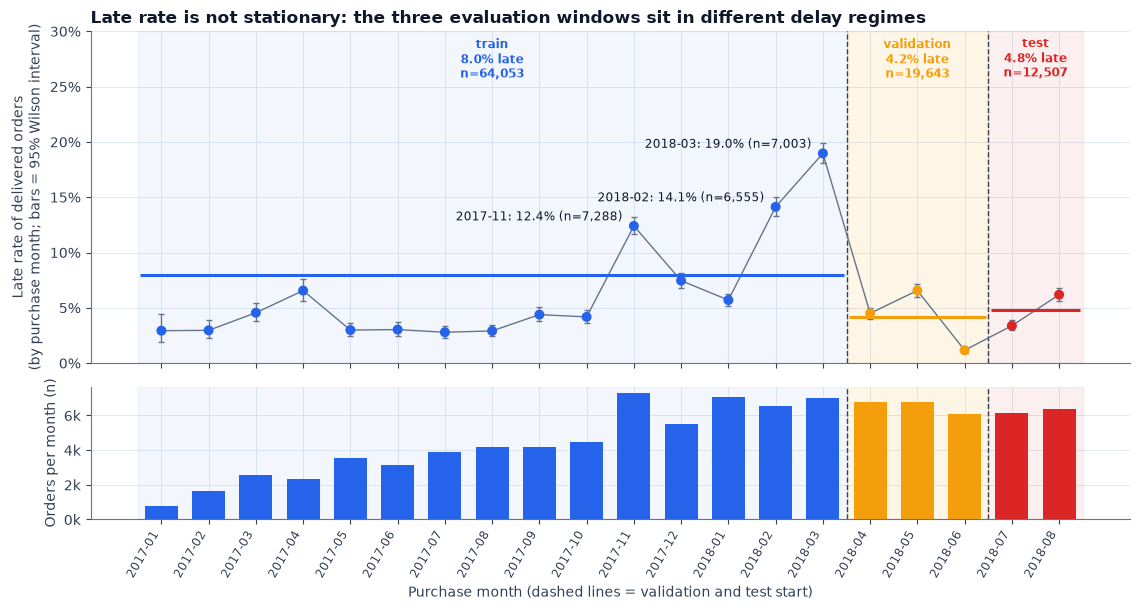

Months plotted:  20 | smallest monthly n: 750


In [8]:
mo = pd.DataFrame(monthly)
mo = mo[mo["month"] >= tm.TRAIN_START[:7]].reset_index(drop=True)
pos = np.arange(len(mo))
def window_of(m):
    return "train" if m < tm.VALIDATION_START[:7] else ("validation" if m < tm.TEST_START[:7] else "test")
mo["window"] = mo["month"].map(window_of)
wcol = {"train": P["blue"], "validation": P["amber"], "test": P["red"]}
z = 1.96
k = mo["late_rate"] * mo["n"]
phat = mo["late_rate"]
den = 1 + z**2 / mo["n"]
ctr = (phat + z**2 / (2 * mo["n"])) / den
hw = z * np.sqrt(phat * (1 - phat) / mo["n"] + z**2 / (4 * mo["n"] ** 2)) / den

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
b1 = pos[mo["window"] == "validation"][0] - 0.5
b2 = pos[mo["window"] == "test"][0] - 0.5
for a in (ax, ax2):
    a.axvspan(-0.5, b1, color=P["blue"], alpha=0.05)
    a.axvspan(b1, b2, color=P["amber"], alpha=0.10)
    a.axvspan(b2, pos[-1] + 0.5, color=P["red"], alpha=0.07)
    a.axvline(b1, color=P["slate"], lw=1, ls="--"); a.axvline(b2, color=P["slate"], lw=1, ls="--")
ax.errorbar(pos, mo["late_rate"], yerr=[mo["late_rate"] - (ctr - hw), (ctr + hw) - mo["late_rate"]], fmt="none", ecolor=P["slate_light"], lw=1, capsize=2)
ax.plot(pos, mo["late_rate"], color=P["slate_light"], lw=1)
ax.scatter(pos, mo["late_rate"], c=[wcol[w] for w in mo["window"]], s=38, zorder=3)
for w, ls in (("train", None), ("validation", None), ("test", None)):
    m = mo["window"] == w
    ax.hlines(parts[w][tm.TARGET].mean(), pos[m][0] - 0.45, pos[m][-1] + 0.45, color=wcol[w], lw=2.2, zorder=2)
    ax.text(pos[m].mean(), 0.295, f"{w}\n{parts[w][tm.TARGET].mean():.1%} late\nn={len(parts[w]):,}",
            ha="center", va="top", fontsize=8.5, color=wcol[w], fontweight="bold")
top = mo.sort_values("late_rate", ascending=False).head(3)
for _, r in top.iterrows():
    ax.annotate(f"{r['month']}: {r['late_rate']:.1%} (n={int(r['n']):,})", (pos[mo['month'] == r['month']][0], r["late_rate"]),
                xytext=(-8, 4), textcoords="offset points", fontsize=8.5, color=P["navy"], ha="right")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, 0.30)
ax.set_ylabel("Late rate of delivered orders\n(by purchase month; bars = 95% Wilson interval)")
ax.set_title("Late rate is not stationary: the three evaluation windows sit in different delay regimes")
ax2.bar(pos, mo["n"], color=[wcol[w] for w in mo["window"]], width=0.7)
ax2.set_ylabel("Orders per month (n)"); ax2.set_xlabel("Purchase month (dashed lines = validation and test start)")
ax2.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax2.set_xticks(pos); ax2.set_xticklabels(mo["month"], rotation=60, ha="right", fontsize=8.5)
save_show(fig, "32_monthly_late_rate_with_splits")
print("Months plotted: ", len(mo), "| smallest monthly n:", int(mo["n"].min()))

In [9]:
print("Notes generated by the training script from the data (split_notes):\n")
for i, n_ in enumerate(notes, 1):
    wrap(f"{i}. {n_}")
    print()

Notes generated by the training script from the data (split_notes):

1. 267 orders purchased before 2017-01-01 (2016-09 to 2016-12) are excluded: the marketplace had almost no volume yet
(at most 265 orders in any month), too sparse to learn from or evaluate on.

2. Late rate by window: train 7.98% (n=64,053), validation 4.17% (n=19,643), test 4.81% (n=12,507). The spread between
the highest and lowest window is 3.8 percentage points, so thresholds and probabilities fitted on one regime are
applied to another and test precision / calibration can differ from validation partly because of the base-rate shift.

3. Non-stationarity: Late rate by month inside the training window: highest 2018-03 (19.0%), 2018-02 (14.1%), 2017-11
(12.4%) versus a median of 4.4%. The top month is 4.3x the median: episodes of elevated delay like this may not be
anticipated from purchase-time order attributes alone, which would limit any purchase-time model.

4. Covariate / concept drift (descriptive, computed p

In [10]:
# Is the shift also visible in the features themselves?  Per window: promise length, same-state share, and the
# same-state vs other-state late-rate gap (descriptive, computed from the labelled data).
rows = []
for k_, v in parts.items():
    g = v.groupby(v["same_state"].astype(int))[tm.TARGET].agg(["mean", "size"])
    rows.append({"window": k_, "n": len(v), "median promise (days)": v["estimated_delivery_days"].astype(float).median(),
                 "same-state share": (v["same_state"].astype(int) == 1).mean(),
                 "late rate, same-state": g.loc[1, "mean"], "late rate, other-state": g.loc[0, "mean"],
                 "gap (same - other, pp)": 100 * (g.loc[1, "mean"] - g.loc[0, "mean"])})
drift = pd.DataFrame(rows).set_index("window")
display(drift)
for k_ in drift.index:
    QUOTED[f"gap_{k_}"] = f"{drift.loc[k_, 'gap (same - other, pp)']:+.1f}"
    QUOTED[f"promise_{k_}"] = f"{drift.loc[k_, 'median promise (days)']:.0f} days"

shift = tm.support_shift(parts, numeric)
for k_, v in shift.items():
    print(f"{k_:<11}: {pct(v['share_outside'], 2):>6} of {v['n']:,} orders have a numeric feature outside the TRAIN range "
          f"(n={v['n_outside']:,}, late rate {pct(v['late_rate_outside'], 1)} vs {pct(v['late_rate_inside'], 1)} for the rest)")
QUOTED["test_outside_share"] = pct(shift["test"]["share_outside"], 1)
QUOTED["test_outside_n"] = f"{shift['test']['n_outside']:,}"
QUOTED["test_outside_rate"] = pct(shift["test"]["late_rate_outside"], 1)
QUOTED["test_inside_rate"] = pct(shift["test"]["late_rate_inside"], 1)

,n,median promise (days),same-state share,"late rate, same-state","late rate, other-state","gap (same - other, pp)"
window,,,,,,
train,64053,24.0000,0.3387,0.0462,0.0970,-5.0806
validation,19643,25.0000,0.3944,0.0228,0.0541,-3.1212
test,12507,17.0000,0.4130,0.0742,0.0297,4.4461


validation :  0.02% of 19,643 orders have a numeric feature outside the TRAIN range (n=3, late rate 0.0% vs 4.2% for the rest)
test       : 10.10% of 12,507 orders have a numeric feature outside the TRAIN range (n=1,263, late rate 16.9% vs 3.5% for the rest)


In [11]:
# Why a random split would flatter the model: shuffle the SAME 2017-01..2018-08 orders into 80 % / 20 %
# and train the SAME logistic regression.  (Demonstration only; this is NOT how the model is evaluated.)
pool = pd.concat([tr, va, te])
rtr, rte = train_test_split(pool, test_size=0.20, stratify=pool[tm.TARGET], random_state=config.RANDOM_STATE)
rand_pipe = tm.build_pipeline(LogisticRegression(max_iter=3000, C=1.0, random_state=config.RANDOM_STATE), numeric, categorical, scale=True)
rand_pipe.fit(rtr[cols], rtr[tm.TARGET])
pr_ = rand_pipe.predict_proba(rte[cols])[:, 1]
chron_pipe = tm.build_pipeline(LogisticRegression(max_iter=3000, C=1.0, random_state=config.RANDOM_STATE), numeric, categorical, scale=True)
chron_pipe.fit(tr[cols], tr[tm.TARGET])
pc_ = chron_pipe.predict_proba(te[cols])[:, 1]
cmp_split = pd.DataFrame({
    "evaluation": ["random 80/20 split of all modelled orders", "chronological: train on earliest, test on latest window"],
    "test n": [len(rte), len(te)], "test late rate": [rte[tm.TARGET].mean(), te[tm.TARGET].mean()],
    "ROC-AUC": [roc_auc_score(rte[tm.TARGET], pr_), roc_auc_score(te[tm.TARGET], pc_)],
    "PR-AUC": [average_precision_score(rte[tm.TARGET], pr_), average_precision_score(te[tm.TARGET], pc_)],
    "PR-AUC lift over no-skill": [average_precision_score(rte[tm.TARGET], pr_) / rte[tm.TARGET].mean(), average_precision_score(te[tm.TARGET], pc_) / te[tm.TARGET].mean()],
})
display(cmp_split.set_index("evaluation"))
QUOTED["rand_auc"] = f"{cmp_split.loc[0, 'ROC-AUC']:.3f}"
QUOTED["rand_lift"] = f"{cmp_split.loc[0, 'PR-AUC lift over no-skill']:.1f}"
QUOTED["chron_auc"] = f"{cmp_split.loc[1, 'ROC-AUC']:.3f}"
QUOTED["chron_lift"] = f"{cmp_split.loc[1, 'PR-AUC lift over no-skill']:.1f}"

,test n,test late rate,ROC-AUC,PR-AUC,PR-AUC lift over no-skill
evaluation,,,,,
random 80/20 split of all modelled orders,19241,0.0679,0.7122,0.1617,2.3821
"chronological: train on earliest, test on latest window",12507,0.0481,0.6189,0.0793,1.6505


**Interpretation — windows, selection bias and non-stationarity.**

* **Counts.** Train **64,053** orders (**5,110** late, **8.0%**), validation **19,643** (**820** late, **4.2%**), test **12,507** (**601** late, **4.8%**). **267** earlier orders are excluded as too sparse.
  Each window has hundreds of late orders, enough for rates with intervals but not enough for fine segment-level conclusions.
* **The late rate is not stationary.** Inside the training window it ranges from about 3% (mid-2017) to **12.4% (Nov 2017)**, **14.1% (Feb 2018)** and **19.0% (Mar 2018)**, then falls back to 4.5% in April 2018.
  Those episodes are not explained by order attributes available at purchase, so any purchase-time model can at best capture a rough average level plus structural differences (promise length, geography).
  The training window deliberately contains the disrupted months so the model has seen both regimes, which also means its *average* training late rate (8.0%) is much higher than in the later windows.
* **Selection bias / right-censoring.** Labels exist only for delivered orders. In the test window **145** of 12,824 orders (**1.13%**) were still in an open status at the end of the data and cannot be labelled; if those are
  disproportionately late, the late rate of the latest months is slightly understated. Cancelled and unavailable orders are also unlabelled, so every rate describes *delivered* orders only.
* **Covariate / concept drift.** The median promise was **24 days** in train, **25 days** in validation and only **17 days** in test. The gap between same-state and other-state late rates is **-5.1** percentage points in train and
  **-3.1** in validation but **+4.4** in test, so the association with `same_state` **changes sign**. In the test window **10.1%** of orders (**1,263**) have a feature outside the training range (almost all: a shorter promise than ever seen in training),
  and those orders are late **16.9%** of the time versus **3.5%** for the rest. The model has to extrapolate on exactly the orders that are most often late.
* **Why not a random split?** Shuffling the same 2017-01 … 2018-08 orders into 80% / 20% gives a ROC-AUC of **0.712** and a PR-AUC lift of **2.4**× over no skill, against **0.619** and **1.7**× when the model must predict a later window.
  Random splitting lets the model see neighbouring days of the same disruption episodes, which flatters it. This is a demonstration of optimism, not an evaluation we rely on.

## 4. The preprocessing pipeline

`src.train_model.build_pipeline` is the single source of truth for the model structure: the notebook, the training script and the saved bundle all use it, so the app scores new orders with exactly the transformations used in training.
Everything is *inside* the scikit-learn `Pipeline`, so nothing leaks from validation or test data into the fitted preprocessing.

In [12]:
lr_template = tm.build_pipeline(LogisticRegression(max_iter=3000, C=1.0, random_state=config.RANDOM_STATE), numeric, categorical, scale=True)
print(lr_template)

Pipeline(steps=[('coerce',
                 FunctionTransformer(func=<function coerce_feature_frame at 0x11e57d4e0>,
                                     kw_args={'categorical': ['customer_state',
                                                              'seller_state',
                                                              'product_category',
                                                              'same_state'],
                                              'numeric': ['n_items',
                                                          'n_sellers',
                                                          'total_price',
                                                          'total_freight',
                                                          'freight_ratio',
                                                          'total_weight_g',
                                                          'total_volume_cm3',
                                                 

In [13]:
steps = pd.DataFrame([
    ("coerce", "prediction.coerce_feature_frame", "numeric -> float64, categorical -> plain strings; raises if a column is missing", "stateless"),
    ("num / impute", "SimpleImputer(median, add_indicator=True)", "fill missing numbers with the TRAIN median; add a 0/1 'was missing' column where any value was missing in train", "fitted on train only"),
    ("num / scale", "StandardScaler (logistic regression only)", "mean 0, SD 1 so the L2 penalty treats features alike; trees skip this step", "fitted on train only"),
    ("cat / impute", "SimpleImputer(constant 'missing')", "an unknown category becomes its own level", "stateless"),
    ("cat / onehot", f"OneHotEncoder(min_frequency={tm.MIN_FREQUENCY}, handle_unknown='ignore')", "one 0/1 column per frequent level; rarer levels are pooled into 'infrequent'; unseen levels become all-zero", "levels learned on train only"),
    ("model", "Dummy / LogisticRegression / RandomForest / HistGradientBoosting", "the estimator being compared", "fitted on train only"),
], columns=["step", "component", "what it does", "state learned from"])
display(steps)

lr_template.fit(tr[cols], tr[tm.TARGET])
prep = lr_template.named_steps["prep"]
Xt = prep.transform(lr_template.named_steps["coerce"].transform(tr[cols]))
names = prep.get_feature_names_out()
print(f"\nInput columns: {len(cols)}   ->   design-matrix columns after preprocessing: {Xt.shape[1]}  (train rows: {Xt.shape[0]:,})")
kinds = pd.Series([n_.split("__")[0] + ("_missing_flag" if "missingindicator" in n_ else "") for n_ in names]).value_counts()
display(kinds.rename("columns").to_frame())
QUOTED["design_cols"] = f"{Xt.shape[1]} design-matrix columns"

,step,component,what it does,state learned from
0,coerce,prediction.coerce_feature_frame,"numeric -> float64, categorical -> plain strings; raises if a column is missing",stateless
1,num / impute,"SimpleImputer(median, add_indicator=True)",fill missing numbers with the TRAIN median; add a 0/1 'was missing' column where any value was missing in train,fitted on train only
2,num / scale,StandardScaler (logistic regression only),"mean 0, SD 1 so the L2 penalty treats features alike; trees skip this step",fitted on train only
3,cat / impute,SimpleImputer(constant 'missing'),an unknown category becomes its own level,stateless
4,cat / onehot,"OneHotEncoder(min_frequency=50, handle_unknown='ignore')",one 0/1 column per frequent level; rarer levels are pooled into 'infrequent'; unseen levels become all-zero,levels learned on train only
5,model,Dummy / LogisticRegression / RandomForest / HistGradientBoosting,the estimator being compared,fitted on train only



Input columns: 16   ->   design-matrix columns after preprocessing: 114  (train rows: 64,053)


,columns
cat,97
num,12
num_missing_flag,5


In [14]:
# Evidence that nothing is learned from validation / test data: the fitted imputer medians equal the TRAIN medians.
imp = prep.named_transformers_["num"].named_steps["impute"]
fitted_med = pd.Series(imp.statistics_, index=numeric)
train_med = tr[numeric].astype("float64").median()
miss = pd.DataFrame({"missing share (train)": tr[numeric].astype("float64").isna().mean(),
                     "median used for imputation": fitted_med,
                     "median of train": train_med,
                     "median of test (for contrast)": te[numeric].astype("float64").median()})
display(miss[miss["missing share (train)"] > 0].assign(**{"n missing (train)": lambda d: (d["missing share (train)"] * len(tr)).round().astype(int)}))
assert np.allclose(fitted_med.to_numpy(), train_med.reindex(numeric).to_numpy(), equal_nan=True)
print("Imputer medians == train-window medians: True")

oh = prep.named_transformers_["cat"].named_steps["onehot"]
rows = []
for c, levels in zip(categorical, oh.categories_):
    vc = tr[c].astype(str).value_counts()
    rows.append({"feature": c, "levels in train": len(levels), "levels kept as own column": int((vc >= tm.MIN_FREQUENCY).sum()),
                 "levels pooled as 'infrequent'": int((vc < tm.MIN_FREQUENCY).sum()),
                 "train orders in pooled levels": int(vc[vc < tm.MIN_FREQUENCY].sum())})
display(pd.DataFrame(rows).set_index("feature"))

,missing share (train),median used for imputation,median of train,median of test (for contrast),n missing (train)
total_weight_g,0.0002,800.0000,800.0000,600.0000,16
total_volume_cm3,0.0002,"7,752.0000","7,752.0000","5,880.0000",16
max_product_length_cm,0.0002,25.0000,25.0000,23.0000,16
max_product_height_cm,0.0002,13.0000,13.0000,13.0000,16
max_product_width_cm,0.0002,20.0000,20.0000,19.0000,16


Imputer medians == train-window medians: True


,levels in train,levels kept as own column,levels pooled as 'infrequent',train orders in pooled levels
feature,,,,
customer_state,27,25,2,73
seller_state,22,14,8,136
product_category,73,53,20,386
same_state,2,2,0,0


**Interpretation.**

* 16 input columns become **114 design-matrix columns**: the 12 numeric columns, 5 "was missing" indicator columns (only the product weight and dimension columns ever have missing values, 16 training orders), and 97 one-hot columns.
* The imputer medians are the training medians (checked above); the test-window medians differ (for example the median weight is lower), which would be a form of leakage if they had been used.
* Rare categories (fewer than 50 training orders) are pooled into an "infrequent" level per feature: this affects only a few hundred training orders and keeps the one-hot design stable. Unseen categories at prediction time become all-zero rows instead of errors.
* Scaling is applied only for logistic regression; the tree models are scale-free.

## 5. Baseline and candidate models

| model | role | tuning (validation PR-AUC, small grids) |
|---|---|---|
| Dummy (class prior) | the **no-skill baseline**: always predicts the training late rate | none |
| Logistic regression | simple, interpretable, strong on sparse one-hot data | `C` × `class_weight` (10 settings) |
| Random forest (300 trees) | non-linear, handles interactions | `min_samples_leaf` × `max_features` (6 settings) |
| Histogram gradient boosting | strong non-linear baseline | `max_iter` × `max_leaf_nodes` (4 settings) |

After tuning, each model is **probability-calibrated** (sigmoid or isotonic, fitted on the earlier half of validation and kept only if it improves Brier score and log-loss on the later half; the final calibrator is refitted on all of validation).
Exact-zero isotonic scores are floored at a small positive probability because no order is certain to be on time.

**Runtime note.** The logistic-regression grid is cheap and is **re-run in full** here. The random-forest and boosting grids dominate the training time, so for those two the notebook refits only the **saved best setting**
and shows the grid results stored in `models/model_metrics.json`. The notebook then reconciles every model, window and metric with that file.

In [15]:
yva, yte, ytr = va[tm.TARGET].to_numpy(), te[tm.TARGET].to_numpy(), tr[tm.TARGET].to_numpy()
fitted: dict[str, dict] = {}
t = time.time()
dummy = tm.build_pipeline(DummyClassifier(strategy="prior"), numeric, categorical, scale=False).fit(tr[cols], ytr)
fitted["dummy_prior"] = {"base": dummy, "best_params": {"strategy": "prior"}, "grid": [],
                         "calibration": {"estimator": dummy, "calibrated": False, "method": None,
                                         "diagnostics": {"reason": "constant prior probability; nothing to calibrate"}}}
tuning_note = {}
for name, (factory, full_grid) in tm.candidate_estimators(quick=False).items():
    t1 = time.time()
    if name == "logistic_regression":
        grid, tuning_note[name] = full_grid, f"full grid of {len(full_grid)} settings re-run here"
    else:   # the tree ensembles are the slow ones: refit only the saved best setting (grid results are shown from the JSON)
        grid, tuning_note[name] = [saved["models"][name]["best_params"]], f"saved best setting refitted (grid of {len(full_grid)} settings read from model_metrics.json)"
    res = tm.fit_and_tune(name, factory, grid, parts, numeric, categorical)
    if name == "logistic_regression":
        assert res["best_params"] == saved["models"][name]["best_params"], "tuning disagrees with the saved model"
    res["calibration"] = tm.calibrate(res["base"], parts, cols)
    fitted[name] = res
    print(f"{name:<24} fitted in {time.time() - t1:5.1f}s | {tuning_note[name]} | best {res['best_params']} | calibration: {res['calibration']['method']}")
print(f"\nAll models fitted in {time.time() - t:.0f}s")

logistic_regression      fitted in   9.9s | full grid of 10 settings re-run here | best {'C': 1.0, 'class_weight': None} | calibration: isotonic


random_forest            fitted in  21.8s | saved best setting refitted (grid of 6 settings read from model_metrics.json) | best {'min_samples_leaf': 10, 'max_features': 0.3} | calibration: isotonic


hist_gradient_boosting   fitted in  12.6s | saved best setting refitted (grid of 4 settings read from model_metrics.json) | best {'max_iter': 250, 'max_leaf_nodes': 8} | calibration: sigmoid

All models fitted in 45s


In [16]:
# Hyper-parameter grids: validation PR-AUC per setting (logistic regression: re-run here; others: saved results).
rows = []
for name in ("logistic_regression", "random_forest", "hist_gradient_boosting"):
    grid = fitted[name]["grid"] if name == "logistic_regression" else saved["models"][name]["tuning_grid"]
    for g in grid:
        rows.append({"model": tm.MODEL_LABELS[name], "setting": json.dumps(g["params"]), "validation PR-AUC": g["validation_pr_auc"],
                     "chosen": g["params"] == saved["models"][name]["best_params"]})
grid_df = pd.DataFrame(rows)
display(grid_df.style.apply(lambda r: ["font-weight: bold; background-color: #DBEAFE" if r["chosen"] else "" for _ in r], axis=1)
        .format({"validation PR-AUC": "{:.4f}"}).hide(axis="index"))
lr_rerun = pd.DataFrame(fitted["logistic_regression"]["grid"])
lr_saved = pd.DataFrame(saved["models"]["logistic_regression"]["tuning_grid"])
print("Logistic-regression grid re-run vs saved grid: max |difference| in validation PR-AUC =",
      f"{np.abs(lr_rerun['validation_pr_auc'].to_numpy() - lr_saved['validation_pr_auc'].to_numpy()).max():.2e}")

# Calibration decision per model (judged on the LATER half of validation, fitted on the earlier half)
rows = []
for name in ("logistic_regression", "random_forest", "hist_gradient_boosting"):
    d = fitted[name]["calibration"]["diagnostics"]
    rows.append({"model": tm.MODEL_LABELS[name], "raw Brier": d["raw"]["brier"], "sigmoid Brier": d["sigmoid"]["brier"],
                 "isotonic Brier": d["isotonic"]["brier"], "decision": d["decision"]})
display(pd.DataFrame(rows).set_index("model"))

model,setting,validation PR-AUC,chosen
Logistic regression,"{""C"": 0.01, ""class_weight"": null}",0.1221,False
Logistic regression,"{""C"": 0.01, ""class_weight"": ""balanced""}",0.1223,False
Logistic regression,"{""C"": 0.03, ""class_weight"": null}",0.1290,False
Logistic regression,"{""C"": 0.03, ""class_weight"": ""balanced""}",0.1269,False
Logistic regression,"{""C"": 0.1, ""class_weight"": null}",0.1354,False
Logistic regression,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.1296,False
Logistic regression,"{""C"": 0.3, ""class_weight"": null}",0.1380,False
Logistic regression,"{""C"": 0.3, ""class_weight"": ""balanced""}",0.1308,False
Logistic regression,"{""C"": 1.0, ""class_weight"": null}",0.1385,True
Logistic regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.1310,False


Logistic-regression grid re-run vs saved grid: max |difference| in validation PR-AUC = 0.00e+00


,raw Brier,sigmoid Brier,isotonic Brier,decision
model,,,,
Logistic regression,0.0345,0.0334,0.0333,isotonic calibration kept; refitted on full validation
Random forest,0.0369,0.0334,0.0334,isotonic calibration kept; refitted on full validation
Histogram gradient boosting,0.0351,0.0330,0.0331,sigmoid calibration kept; refitted on full validation


In [17]:
# Scores on both windows with the deployment rules of the training script: calibrated estimator, exact-zero floor,
# F1-optimal threshold chosen on VALIDATION only.
val_raw = {n_: r["calibration"]["estimator"].predict_proba(va[cols])[:, 1] for n_, r in fitted.items()}
floors = {n_: tm.probability_floor(val_raw[n_], yva) for n_ in fitted}
val_scores = {n_: np.maximum(val_raw[n_], floors[n_]) for n_ in fitted}
test_scores = {n_: tm._proba(r["calibration"]["estimator"], te[cols], floors[n_]) for n_, r in fitted.items()}
test_base = {n_: r["base"].predict_proba(te[cols])[:, 1] for n_, r in fitted.items()}
val_base = {n_: r["base"].predict_proba(va[cols])[:, 1] for n_, r in fitted.items()}
thresholds = {n_: (0.5 if n_ == "dummy_prior" else tm.f1_optimal_threshold(yva, val_scores[n_])) for n_ in fitted}

met = {n_: {"validation": tm.classification_metrics(yva, val_scores[n_], thresholds[n_]),
            "test": tm.classification_metrics(yte, test_scores[n_], thresholds[n_])} for n_ in fitted}

# Reconcile with the numbers stored in models/model_metrics.json (written by `python -m src.train_model`).
keys = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier", "log_loss"]
rows, worst_by_model = [], {}
for n_ in fitted:
    for w in ("validation", "test"):
        dev_ = max(abs(met[n_][w][k_] - saved["models"][n_][w][k_]) for k_ in keys)
        worst_by_model[n_] = max(worst_by_model.get(n_, 0.0), dev_)
        rows.append({"model": tm.MODEL_LABELS[n_], "window": w, "this notebook: PR-AUC": met[n_][w]["pr_auc"],
                     "saved: PR-AUC": saved["models"][n_][w]["pr_auc"], "this notebook: ROC-AUC": met[n_][w]["roc_auc"],
                     "saved: ROC-AUC": saved["models"][n_][w]["roc_auc"], "max |diff| over 8 metrics": dev_})
display(pd.DataFrame(rows).set_index(["model", "window"]).style.format("{:.4f}", subset=pd.IndexSlice[:, ["this notebook: PR-AUC", "saved: PR-AUC", "this notebook: ROC-AUC", "saved: ROC-AUC"]]).format("{:.1e}", subset=["max |diff| over 8 metrics"]))
for n_ in fitted:
    assert abs(thresholds[n_] - saved["models"][n_]["threshold"]) < 1e-9, n_
print("Largest deviation from the saved metrics, per model:", {k_: f"{v_:.1e}" for k_, v_ in worst_by_model.items()})
worst = max(v_ for k_, v_ in worst_by_model.items() if k_ != "random_forest")
assert worst < 1e-9, f"notebook disagrees with the saved metrics (max diff {worst})"
assert worst_by_model["random_forest"] < 1e-3, "random forest deviates by more than float-summation noise"
print("Dummy, logistic regression and gradient boosting reproduce models/model_metrics.json to floating-point precision.")
print("The random forest agrees to within the small deviation explained below.")

Largest deviation from the saved metrics, per model: {'dummy_prior': '0.0e+00', 'logistic_regression': '0.0e+00', 'random_forest': '2.6e-04', 'hist_gradient_boosting': '0.0e+00'}
Dummy, logistic regression and gradient boosting reproduce models/model_metrics.json to floating-point precision.
The random forest agrees to within the small deviation explained below.


In [18]:
# Why the random forest is not bit-identical: its predict_proba sums tree outputs across threads, so the last bits of each
# probability depend on thread timing (~1e-16).  The isotonic calibrator then sorts / pools tied scores, which amplifies that
# noise to ~1e-4 in the metrics.  Re-running the SAME calibration on the SAME forest shows it:
rf_base = fitted["random_forest"]["base"]
p_a = rf_base.predict_proba(va[cols])[:, 1]; p_b = rf_base.predict_proba(va[cols])[:, 1]
print(f"two predict_proba calls on the same forest: max |difference| = {np.abs(p_a - p_b).max():.1e}")
reps = []
for _ in range(3):
    c_ = tm.calibrate(rf_base, parts, cols)["estimator"]
    reps.append(average_precision_score(yva, c_.predict_proba(va[cols])[:, 1]))
print("validation PR-AUC of the re-calibrated forest, three repeats:", ", ".join(f"{v_:.5f}" for v_ in reps),
      f"| saved: {saved['models']['random_forest']['validation']['pr_auc']:.5f}")
print(f"spread between repeats: {max(reps) - min(reps):.1e}  (same order as the deviation from the saved file: {worst_by_model['random_forest']:.1e})")

two predict_proba calls on the same forest: max |difference| = 1.7e-16


validation PR-AUC of the re-calibrated forest, three repeats: 0.11735, 0.11751, 0.11718 | saved: 0.11747
spread between repeats: 3.3e-04  (same order as the deviation from the saved file: 2.6e-04)


**Interpretation.**

* The re-run logistic-regression grid reproduces the saved grid exactly and picks the same setting (`C = 1.0`, no class weighting). Class weighting (`balanced`) was not better than no weighting at any `C` of 0.03 or more (it was marginally higher only at `C` = 0.01).
* **Reconciliation with `models/model_metrics.json`:** the dummy, logistic regression and histogram gradient boosting match the saved file to floating-point precision (deviation 0).
  The **random forest deviates by about 1e-04** (largest difference over eight metrics). This is not a code difference: the forest sums tree outputs across threads, so each probability varies in its last bits (about 1e-16),
  and the isotonic calibrator, which pools tied scores, amplifies this to about 1e-4. Re-running the *same* calibration on the *same* forest three times gives validation PR-AUCs that differ among themselves by about 2e-4 (cell above).
  The selected model, logistic regression, is deterministic and matches exactly.
* Calibration was kept for all three tuned models (isotonic for logistic regression and the forest, sigmoid for boosting) because it improved the Brier score on the later half of validation (for logistic regression 0.0345 → 0.0333).
  Calibration was judged on validation, not on test: later we will see that it does not protect against a base-rate shift.

## 6. Evaluation

### Which metrics matter for delay-risk prediction, and why accuracy misleads

* **Accuracy** counts correct labels. With about 5% late orders, predicting "on time" for everything scores about 95% and finds no late order at all.
* **Recall** (share of late orders that are flagged) and **precision** (share of flagged orders that really are late) describe the trade-off in using the model for triage. They depend on the threshold.
* **PR-AUC (average precision)** summarises precision across all thresholds and focuses on the rare class; its **no-skill value equals the prevalence**, so lift over that baseline is easy to read. It is the primary selection metric here.
* **ROC-AUC** measures ranking quality independent of prevalence (0.5 = no skill) but can look comfortable even when precision is poor.
* **Brier score / log-loss and the calibration curve** check whether a predicted "10%" really means about 10%. A model can rank well and still be badly calibrated after the base rate shifts.
* **Lift in the top 10%** compares the late rate among the 10% highest scores with the overall late rate. The scores are a step function with few distinct levels, so tied scores at the 10% cut are split in expectation (as if broken at random); a plain `argsort` would break the ties by row order and give a somewhat different number.

All thresholds below were fixed on the **validation** window (F1-optimal cut for each model) and then applied unchanged to test.

In [19]:
def metric_table(window: str) -> pd.DataFrame:
    rows = {}
    for n_ in fitted:
        m = met[n_][window]
        rows[tm.MODEL_LABELS[n_]] = {"accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                                     "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"], "Brier": m["brier"], "log-loss": m["log_loss"],
                                     "flagged share": m["predicted_positive_rate"], "lift in top 10 %": m["lift_top10pct"]}
    return pd.DataFrame(rows).T

print(f"TEST window (n={len(te):,}, {pct(yte.mean(), 2)} late) - thresholds frozen on validation; never used for fitting or selection")
display(metric_table("test"))
print(f"VALIDATION window (n={len(va):,}, {pct(yva.mean(), 2)} late) - tuned / in-sample for the selected model, NOT an unbiased estimate")
display(metric_table("validation"))

# Uncertainty on the test window: paired bootstrap of ROC-AUC / PR-AUC (same resamples for every model).
t = time.time()
boot_te = tm.bootstrap_scores(yte, test_scores, 300, config.RANDOM_STATE + 1)
ci = pd.DataFrame({tm.MODEL_LABELS[n_]: {"test ROC-AUC 95% interval": f"{tm._ci(boot_te[n_]['roc_auc'])[0]:.3f} - {tm._ci(boot_te[n_]['roc_auc'])[1]:.3f}",
                                           "test PR-AUC 95% interval": f"{tm._ci(boot_te[n_]['pr_auc'])[0]:.3f} - {tm._ci(boot_te[n_]['pr_auc'])[1]:.3f}"} for n_ in fitted}).T
display(ci)
print(f"bootstrap done in {time.time() - t:.0f}s;  no-skill PR-AUC on test = late rate = {yte.mean():.3f}")
for n_ in ("logistic_regression", "hist_gradient_boosting"):
    assert [round(v, 9) for v in tm._ci(boot_te[n_]["pr_auc"])] == [round(v, 9) for v in saved["models"][n_]["test_ci95"]["pr_auc"]]
print("Bootstrap intervals identical to the saved ones (logistic regression, gradient boosting): True")
ci_lr_auc, ci_lr_pr = tm._ci(boot_te["logistic_regression"]["roc_auc"]), tm._ci(boot_te["logistic_regression"]["pr_auc"])

L, D = met["logistic_regression"], met["dummy_prior"]
for w in ("validation", "test"):
    QUOTED[f"lr_{w}_auc"] = f"{L[w]['roc_auc']:.3f}"
    QUOTED[f"lr_{w}_pr"] = f"{L[w]['pr_auc']:.3f}"
    QUOTED[f"lr_{w}_acc"] = pct(L[w]["accuracy"], 1)
    QUOTED[f"lr_{w}_prec"] = pct(L[w]["precision"], 1)
    QUOTED[f"lr_{w}_rec"] = pct(L[w]["recall"], 1)
    QUOTED[f"lr_{w}_f1"] = f"{L[w]['f1']:.3f}"
    QUOTED[f"lr_{w}_brier"] = f"{L[w]['brier']:.4f}"
    QUOTED[f"lr_{w}_flag"] = pct(L[w]["predicted_positive_rate"], 1)
    QUOTED[f"lr_{w}_lift10"] = f"{L[w]['lift_top10pct']:.1f}"
QUOTED["dummy_test_acc"] = pct(D["test"]["accuracy"], 1)
QUOTED["dummy_test_brier"] = f"{D['test']['brier']:.4f}"
QUOTED["dummy_val_pr"] = f"{D['validation']['pr_auc']:.3f}"
QUOTED["dummy_test_pr"] = f"{D['test']['pr_auc']:.3f}"
QUOTED["lr_test_auc_ci"] = f"{ci_lr_auc[0]:.3f} - {ci_lr_auc[1]:.3f}"
QUOTED["lr_test_pr_ci"] = f"{ci_lr_pr[0]:.3f} - {ci_lr_pr[1]:.3f}"
# the random forest is quoted from the saved file (its last digits move with thread timing, see section 5)
for n_, key in (("random_forest", "rf"), ("hist_gradient_boosting", "hgb")):
    src_ = saved["models"][n_]
    QUOTED[f"{key}_test_auc"] = f"{src_['test']['roc_auc']:.3f}"
    QUOTED[f"{key}_test_pr"] = f"{src_['test']['pr_auc']:.3f}"
    QUOTED[f"{key}_val_auc"] = f"{src_['validation']['roc_auc']:.3f}"
    QUOTED[f"{key}_val_pr"] = f"{src_['validation']['pr_auc']:.3f}"

TEST window (n=12,507, 4.81% late) - thresholds frozen on validation; never used for fitting or selection


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,Brier,log-loss,flagged share,lift in top 10 %
Dummy baseline (class prior),0.9519,0.0000,0.0000,0.0000,0.5000,0.0481,0.0468,0.2006,0.0000,1.0000
Logistic regression,0.7988,0.0697,0.2579,0.1097,0.6174,0.0726,0.0487,0.2019,0.1779,1.7104
Random forest,0.7513,0.0537,0.2512,0.0885,0.5951,0.0587,0.0481,0.2042,0.2248,1.1913
Histogram gradient boosting,0.7522,0.0452,0.2063,0.0741,0.5066,0.0505,0.0504,0.2151,0.2196,1.0646


VALIDATION window (n=19,643, 4.17% late) - tuned / in-sample for the selected model, NOT an unbiased estimate


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC,Brier,log-loss,flagged share,lift in top 10 %
Dummy baseline (class prior),0.9583,0.0000,0.0000,0.0000,0.5000,0.0417,0.0414,0.1852,0.0000,1.0000
Logistic regression,0.9170,0.1927,0.3098,0.2376,0.7813,0.1403,0.0376,0.1508,0.0671,3.9262
Random forest,0.8917,0.1491,0.3390,0.2072,0.7419,0.1172,0.0383,0.1566,0.0949,3.5150
Histogram gradient boosting,0.9004,0.1561,0.3146,0.2087,0.7454,0.1381,0.0381,0.1564,0.0842,3.4988


,test ROC-AUC 95% interval,test PR-AUC 95% interval
Dummy baseline (class prior),0.500 - 0.500,0.044 - 0.051
Logistic regression,0.599 - 0.637,0.064 - 0.083
Random forest,0.576 - 0.614,0.053 - 0.065
Histogram gradient boosting,0.487 - 0.527,0.044 - 0.058


bootstrap done in 5s;  no-skill PR-AUC on test = late rate = 0.048
Bootstrap intervals identical to the saved ones (logistic regression, gradient boosting): True


In [20]:
# Accuracy is misleading at ~5 % prevalence: compare "always predict on time" with the model at its validation threshold.
acc = pd.DataFrame({
    "late orders found (recall)": [met["dummy_prior"]["test"]["recall"], met["logistic_regression"]["test"]["recall"]],
    "late orders found (n)": [met["dummy_prior"]["test"]["confusion_matrix"][1][1], met["logistic_regression"]["test"]["confusion_matrix"][1][1]],
    "accuracy": [met["dummy_prior"]["test"]["accuracy"], met["logistic_regression"]["test"]["accuracy"]],
}, index=["Always predict 'on time' (dummy)", "Logistic regression at the validation-chosen threshold"])
display(acc)
QUOTED["lr_test_tp"] = f"{met['logistic_regression']['test']['confusion_matrix'][1][1]:,}"
QUOTED["test_n_late"] = f"{int(yte.sum()):,}"

,late orders found (recall),late orders found (n),accuracy
Always predict 'on time' (dummy),0.0000,0,0.9519
Logistic regression at the validation-chosen threshold,0.2579,155,0.7988


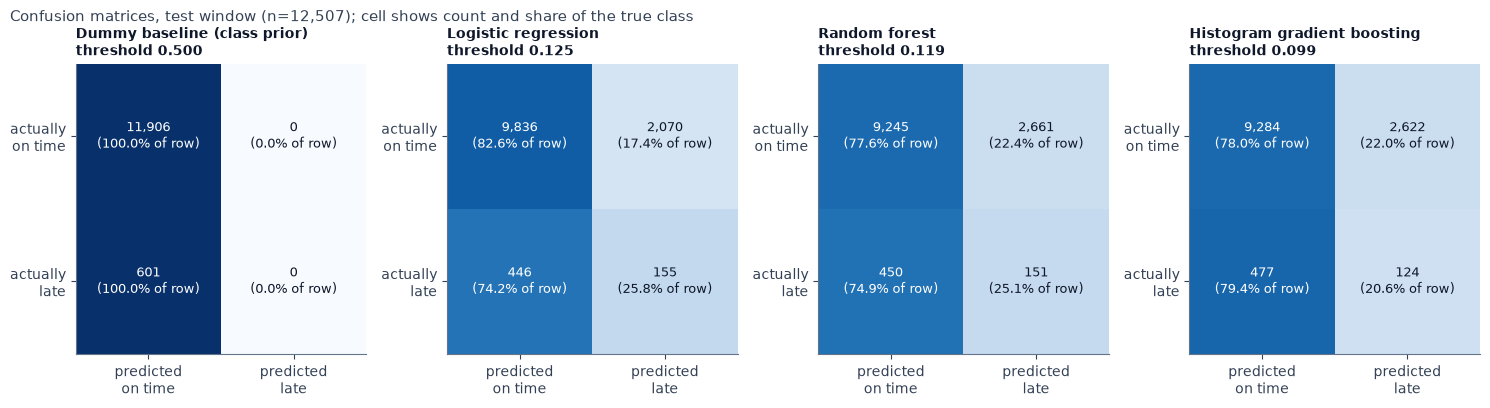

In [21]:
# Confusion matrices on the TEST window (threshold frozen on validation).
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, n_ in zip(axes, fitted):
    cm = np.array(met[n_]["test"]["confusion_matrix"])
    rate = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({rate[i, j]:.1%} of row)", ha="center", va="center", fontsize=9,
                    color="white" if rate[i, j] > 0.55 else P["navy"])
    ax.set_xticks([0, 1], ["predicted\non time", "predicted\nlate"]); ax.set_yticks([0, 1], ["actually\non time", "actually\nlate"])
    ax.grid(False)
    ax.set_title(f"{tm.MODEL_LABELS[n_]}\nthreshold {thresholds[n_]:.3f}", fontsize=10)
fig.suptitle(f"Confusion matrices, test window (n={len(te):,}); cell shows count and share of the true class", x=0.01, ha="left", fontsize=11, color=P["slate"])
save_show(fig, "33_confusion_matrices_test")

Top score bin (logistic regression, test): n=235 of 12,507 orders (1.9%); mean predicted 28.3%, observed 14.0% (~33 late orders), Wilson 95% interval 10.2% - 19.1%
Bin sizes: [1345, 1341, 1444, 1900, 514, 1512, 1215, 1011, 1990, 235]


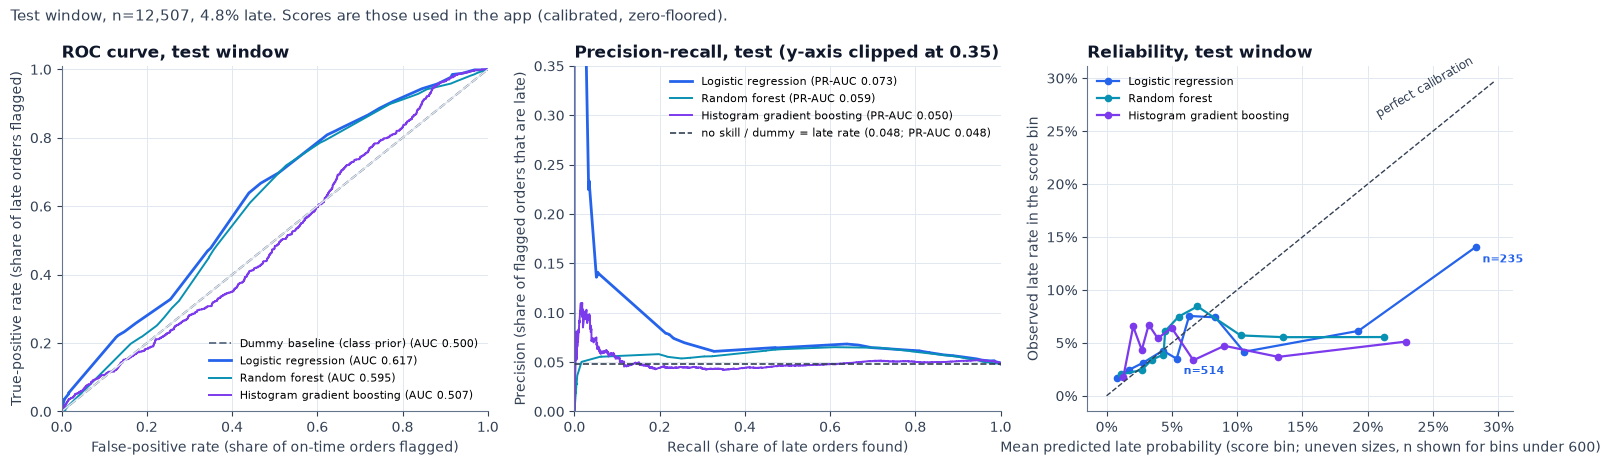

In [22]:
# ROC, precision-recall and calibration curves on the TEST window (all models, final deployed scores).
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.7))
ax = axes[0]
for n_ in fitted:
    fpr, tpr, _ = roc_curve(yte, test_scores[n_])
    ax.plot(fpr, tpr, color=MODEL_COLORS[n_], lw=2 if n_ == "logistic_regression" else 1.4, ls="--" if n_ == "dummy_prior" else "-",
            label=f"{tm.MODEL_LABELS[n_]} (AUC {met[n_]['test']['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=P["border"], lw=1)
ax.set_xlabel("False-positive rate (share of on-time orders flagged)"); ax.set_ylabel("True-positive rate (share of late orders flagged)")
ax.set_title("ROC curve, test window"); ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)

ax = axes[1]
for n_ in ("logistic_regression", "random_forest", "hist_gradient_boosting"):
    pr_, rc_, _ = precision_recall_curve(yte, test_scores[n_])
    ax.plot(rc_, pr_, color=MODEL_COLORS[n_], lw=2 if n_ == "logistic_regression" else 1.4,
            label=f"{tm.MODEL_LABELS[n_]} (PR-AUC {met[n_]['test']['pr_auc']:.3f})")
ax.axhline(yte.mean(), color=P["slate"], ls="--", lw=1.2, label=f"no skill / dummy = late rate ({yte.mean():.3f}; PR-AUC {met['dummy_prior']['test']['pr_auc']:.3f})")
ax.set_xlabel("Recall (share of late orders found)"); ax.set_ylabel("Precision (share of flagged orders that are late)")
ax.set_title("Precision-recall, test (y-axis clipped at 0.35)"); ax.legend(loc="upper right", fontsize=8)
ax.set_xlim(0, 1); ax.set_ylim(0, 0.35)

ax = axes[2]
mx = 0
for n_ in ("logistic_regression", "random_forest", "hist_gradient_boosting"):
    c_ = tm.curve_payloads(yte, test_scores[n_])["cal"]
    ax.plot(c_["mean_predicted"], c_["fraction_positive"], marker="o", ms=4.5, color=MODEL_COLORS[n_], lw=1.6, label=tm.MODEL_LABELS[n_])
    mx = max(mx, max(c_["mean_predicted"]), max(c_["fraction_positive"]))
    if n_ == "logistic_regression":   # bins are NOT equal-sized (tied scores, duplicates='drop'): show n so small bins are visible
        for x_, y_, k_ in zip(c_["mean_predicted"], c_["fraction_positive"], c_["bin_counts"]):
            if k_ < 600:   # only the small bins are labelled (the others hold 1,000-2,000 orders each)
                ax.annotate(f"n={k_:,}", (x_, y_), xytext=(5, -11), textcoords="offset points", fontsize=8, color=MODEL_COLORS[n_], fontweight="bold")
ax.plot([0, mx * 1.05], [0, mx * 1.05], color=P["slate"], ls="--", lw=1)
ax.text(mx * 1.0, mx * 0.93, "perfect calibration", rotation=30, fontsize=8.5, color=P["slate"], ha="right")
ax.set_xlabel("Mean predicted late probability (score bin; uneven sizes, n shown for bins under 600)"); ax.set_ylabel("Observed late rate in the score bin")
ax.set_title("Reliability, test window"); ax.legend(loc="upper left", fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
# Top (highest-scored) bin of the deployed model on test: small, so quote its size and a Wilson 95% interval.
_c = tm.curve_payloads(yte, test_scores["logistic_regression"])["cal"]
_n, _p = int(_c["bin_counts"][-1]), float(_c["fraction_positive"][-1])
_z = 1.959964; _den = 1 + _z**2 / _n
_ctr = (_p + _z**2 / (2 * _n)) / _den; _half = _z * np.sqrt(_p * (1 - _p) / _n + _z**2 / (4 * _n**2)) / _den
print(f"Top score bin (logistic regression, test): n={_n:,} of {len(yte):,} orders ({_n / len(yte):.1%}); "
      f"mean predicted {_c['mean_predicted'][-1]:.1%}, observed {_p:.1%} (~{round(_p * _n)} late orders), Wilson 95% interval {_ctr - _half:.1%} - {_ctr + _half:.1%}")
print("Bin sizes:", _c["bin_counts"])
QUOTED["top_bin_n"] = f"n={_n:,}"
QUOTED["top_bin_pred"] = pct(_c["mean_predicted"][-1], 1)
QUOTED["top_bin_obs"] = pct(_p, 1)
QUOTED["top_bin_ci"] = f"{_ctr - _half:.1%} - {_ctr + _half:.1%}"
fig.suptitle(f"Test window, n={len(te):,}, {pct(yte.mean(), 1)} late. Scores are those used in the app (calibrated, zero-floored).", x=0.01, ha="left", fontsize=10.5, color=P["slate"])
save_show(fig, "34_roc_pr_calibration_test")

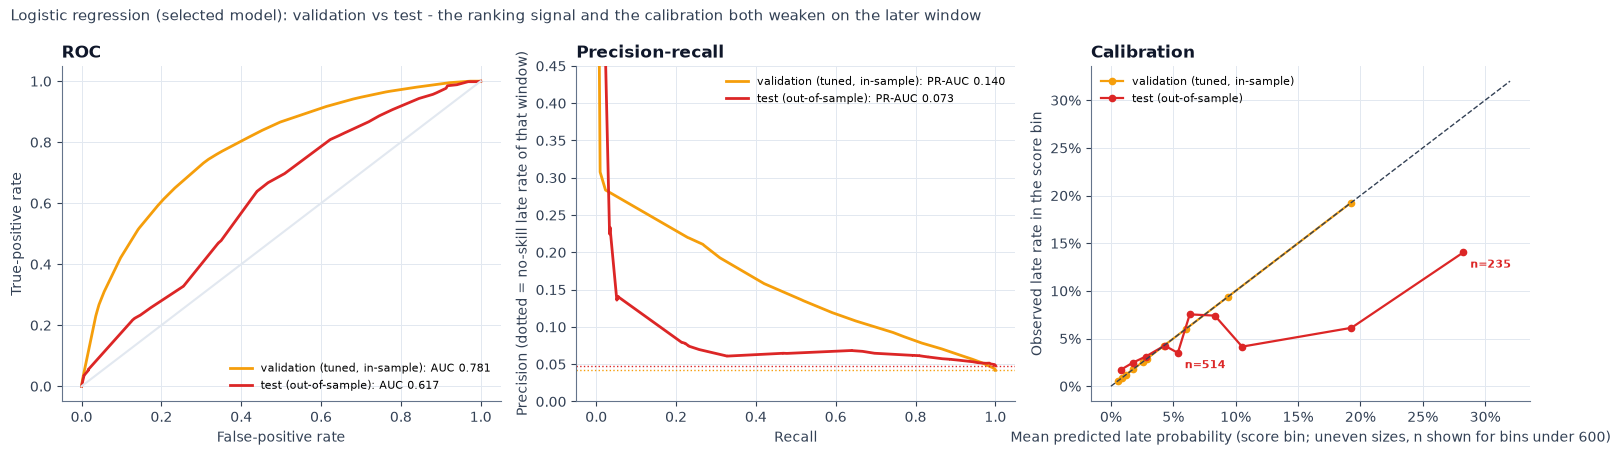

In [23]:
# The selected model on validation vs test: the same code, the same threshold, two windows.
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
sel_name = "logistic_regression"
for w, ys, ps, col, ls in (("validation (tuned, in-sample)", yva, val_scores[sel_name], P["amber"], "-"), ("test (out-of-sample)", yte, test_scores[sel_name], P["red"], "-")):
    fpr, tpr, _ = roc_curve(ys, ps); axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{w}: AUC {roc_auc_score(ys, ps):.3f}")
    pr_, rc_, _ = precision_recall_curve(ys, ps); axes[1].plot(rc_, pr_, color=col, lw=2, label=f"{w}: PR-AUC {average_precision_score(ys, ps):.3f}")
    axes[1].axhline(ys.mean(), color=col, ls=":", lw=1)
    c_ = tm.curve_payloads(ys, ps)["cal"]; axes[2].plot(c_["mean_predicted"], c_["fraction_positive"], marker="o", ms=4.5, color=col, lw=1.6, label=w)
    for x_, y_, k_ in zip(c_["mean_predicted"], c_["fraction_positive"], c_["bin_counts"]):
        if k_ < 600:   # only the small bins are labelled
            axes[2].annotate(f"n={k_:,}", (x_, y_), xytext=(5, 5 if col == P["amber"] else -11), textcoords="offset points", fontsize=8, color=col, fontweight="bold")
axes[0].plot([0, 1], [0, 1], color=P["border"]); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate"); axes[0].set_title("ROC"); axes[0].legend(loc="lower right", fontsize=8)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision (dotted = no-skill late rate of that window)"); axes[1].set_title("Precision-recall"); axes[1].legend(loc="upper right", fontsize=8); axes[1].set_ylim(0, 0.45)
axes[2].plot([0, 0.32], [0, 0.32], color=P["slate"], ls="--", lw=1); axes[2].set_xlabel("Mean predicted late probability (score bin; uneven sizes, n shown for bins under 600)"); axes[2].set_ylabel("Observed late rate in the score bin")
axes[2].set_title("Calibration"); axes[2].legend(loc="upper left", fontsize=8)
axes[2].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); axes[2].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fig.suptitle("Logistic regression (selected model): validation vs test - the ranking signal and the calibration both weaken on the later window", x=0.01, ha="left", fontsize=10.5, color=P["slate"])
save_show(fig, "35_selected_model_validation_vs_test")

**Interpretation (test window unless stated; all figures from the tables and plots above).**

* **Accuracy misleads.** The dummy that never flags an order scores **95.2%** accuracy on test and finds **0 of 601** late orders; logistic regression scores only **79.9%** accuracy yet finds **155** of the **601** late orders (recall **25.8%**).
  The accuracy ranking is the reverse of the usefulness ranking, which is why accuracy is shown but never used to choose a model.
* **Logistic regression, test:** ROC-AUC **0.617** (95% bootstrap interval 0.599 - 0.637), PR-AUC **0.073** (0.064 - 0.083) against a no-skill PR-AUC of **0.048**; precision **7.0%**, recall **25.8%**, F1 **0.110**, with **17.8%** of orders flagged.
  The top-10% lift is only **1.7**. This is a **modest but real** signal: the interval excludes no skill, but the model finds late orders only somewhat better than chance.
* **Validation, tuned / in-sample:** accuracy **91.7%**, Brier **0.0376** (dummy 0.0414), ROC-AUC **0.781**, PR-AUC **0.140** (no skill 0.042), precision **19.3%**, recall **31.0%**, F1 **0.238**, **6.7%** flagged, top-10% lift **3.9**. These look much better and are **not** an honest estimate: every choice was made on this window.
* **Other models.** Random forest: test ROC-AUC **0.595**, PR-AUC **0.059** (validation 0.742 / 0.117, saved file). Histogram gradient boosting: test ROC-AUC **0.507** (indistinguishable from no skill), PR-AUC **0.050** (validation 0.745 / 0.138).
  On validation, gradient boosting matches logistic regression on PR-AUC (0.138 vs 0.140) but is lower on ROC-AUC (0.745 vs 0.781); the random forest is lower on both (0.117 / 0.742). Neither flexible model transfers better to the later window; they transfer **worse**.
  One possible reason is that the more flexible models fit the earlier regime more closely; this notebook does not test that explanation.
* **Calibration and Brier.** Test Brier is **0.0487** for logistic regression versus **0.0468** for the constant dummy: *the model's probabilities are no better than quoting a base rate*, because the mean predicted risk (7.5%) is well above the observed 4.8%.
  The test reliability curve shows the highest-scored bin (**n=235** orders, 1.9% of the test window; the score bins are uneven because many orders share the same score, so they are not equal deciles) predicted at **28.3%** but observed at **14.0%** (Wilson 95% interval **10.2% - 19.1%**, roughly 33 late orders). That bin is small, so treat it as an indication of over-prediction at the top of the score range, not a precise figure. On validation (where calibration was fitted) the curve follows the diagonal, a reminder that calibration is only as good as the stability of the base rate.
* **What the plots add.** The test ROC curve for logistic regression is mostly above the diagonal, but not by much; on the test precision-recall curve precision stays around 6–7% over most of the recall range (no skill 4.8%), and the validation-versus-test comparison shows a clear loss of ranking signal and calibration.

## 7. Threshold and risk-band selection

Two decisions are taken on the **validation** window and then evaluated on test:

1. **Decision threshold** (flag an order as late) — the cut that maximises F1 on validation. F1 balances precision and recall, which suits a triage list; a team with a different review capacity may prefer another cut.
2. **Risk bands** — Low / Moderate / High probability cuts taken from validation score quantiles: High ≈ the top 5% of validation scores, Moderate ≈ the next 15%, Low = the rest. The scores are a step function with few distinct levels, so ties make the actual shares differ slightly from 5% and 15%.

The plot shows precision, recall and F1 against the threshold on validation (where the choice is made) and, for contrast only, on test (nothing is chosen from it).

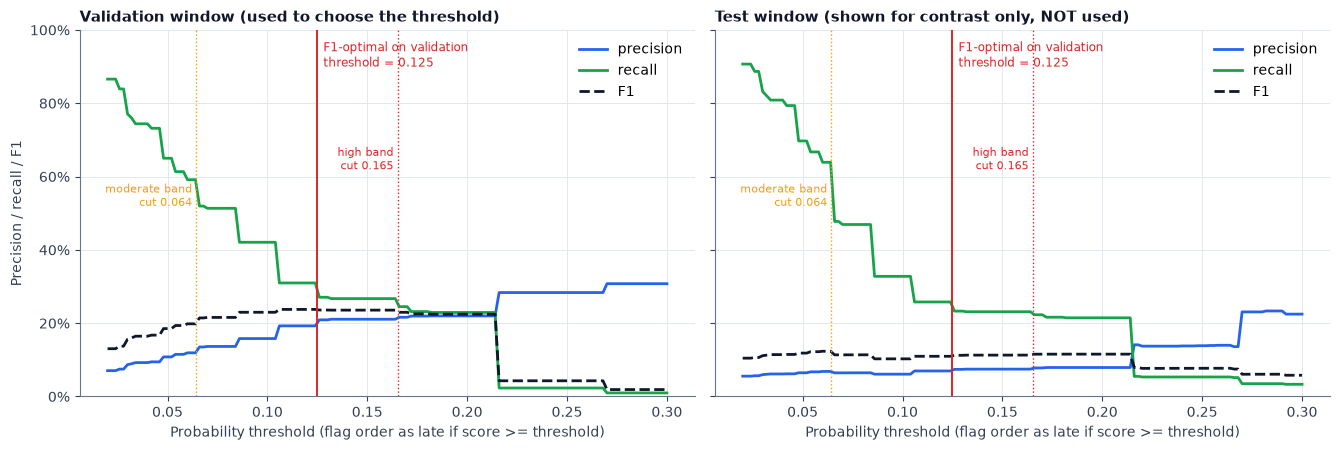

Operating point: flag an order as late when probability >= 0.1250  (the F1-optimal cut on validation)


,validation,test
flagged share of orders,0.0671,0.1779
precision,0.1927,0.0697
recall,0.3098,0.2579
F1,0.2376,0.1097
no-skill precision (late rate),0.0417,0.0481


In [24]:
sel = "logistic_regression"
ps_v, ps_t = val_scores[sel], test_scores[sel]
th = thresholds[sel]
bands_th = tm.risk_thresholds(ps_v)
assert bands_th == saved["risk_bands"]["thresholds"], "risk-band cut points differ from the saved model"

def prf_curve(ys, ps, grid):
    prec, rec, f1, flag = [], [], [], []
    for g in grid:
        pred_ = ps >= g
        tp = int((pred_ & (ys == 1)).sum()); fp = int((pred_ & (ys == 0)).sum()); fn = int((~pred_ & (ys == 1)).sum())
        p_ = tp / (tp + fp) if tp + fp else np.nan; r_ = tp / (tp + fn) if tp + fn else 0.0
        prec.append(p_); rec.append(r_); f1.append(2 * p_ * r_ / (p_ + r_) if tp else 0.0); flag.append(pred_.mean())
    return np.array(prec), np.array(rec), np.array(f1), np.array(flag)

grid = np.linspace(0.02, 0.30, 141)
pv, rv, fv, gv = prf_curve(yva, ps_v, grid)
pt, rt, ft, gt = prf_curve(yte, ps_t, grid)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
for ax, (p_, r_, f_, ttl, ls) in zip(axes, ((pv, rv, fv, "Validation window (used to choose the threshold)", "-"), (pt, rt, ft, "Test window (shown for contrast only, NOT used)", "-"))):
    ax.plot(grid, p_, color=P["blue"], lw=2, label="precision"); ax.plot(grid, r_, color=P["green"], lw=2, label="recall"); ax.plot(grid, f_, color=P["navy"], lw=2, ls="--", label="F1")
    ax.axvline(th, color=P["red"], lw=1.4); ax.text(th + 0.003, 0.9, f"F1-optimal on validation\nthreshold = {th:.3f}", color=P["red"], fontsize=8.5)
    for name_, c_ in (("moderate", P["amber"]), ("high", P["red"])):
        ax.axvline(bands_th[name_], color=c_, lw=1, ls=":")
        ax.text(bands_th[name_] - 0.002, 0.52 if name_ == "moderate" else 0.62, f"{name_} band\ncut {bands_th[name_]:.3f}", color=c_, fontsize=8, ha="right")
    ax.set_title(ttl, fontsize=11); ax.set_xlabel("Probability threshold (flag order as late if score >= threshold)")
    ax.set_ylim(0, 1.0); ax.legend(loc="upper right")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Precision / recall / F1")
save_show(fig, "36_threshold_selection")

tab = pd.DataFrame({"validation": {"flagged share of orders": met[sel]["validation"]["predicted_positive_rate"], "precision": met[sel]["validation"]["precision"],
                                   "recall": met[sel]["validation"]["recall"], "F1": met[sel]["validation"]["f1"], "no-skill precision (late rate)": yva.mean()},
                    "test": {"flagged share of orders": met[sel]["test"]["predicted_positive_rate"], "precision": met[sel]["test"]["precision"],
                             "recall": met[sel]["test"]["recall"], "F1": met[sel]["test"]["f1"], "no-skill precision (late rate)": yte.mean()}})
print(f"Operating point: flag an order as late when probability >= {th:.4f}  (the F1-optimal cut on validation)")
display(tab)

,validation n,validation share,validation late n,validation late rate,validation 95% interval,test n,test share,test late n,test late rate,test 95% interval
band,,,,,,,,,,
Low,15571,0.7927,335,0.0215,1.9% - 2.4%,6890,0.5509,217,0.0315,2.8% - 3.6%
Moderate,3033,0.1544,266,0.0877,7.8% - 9.8%,3756,0.3003,245,0.0652,5.8% - 7.4%
High,1039,0.0529,219,0.2108,18.7% - 23.7%,1861,0.1488,139,0.0747,6.4% - 8.8%


Validation: Observed late rate rises monotonically from Low to High. Adjacent bands have non-overlapping 95% Wilson intervals.
Test      : Observed late rate rises monotonically from Low to High. The 95% Wilson intervals of adjacent bands overlap for Moderate-High: those bands cannot be told apart at this sample size.


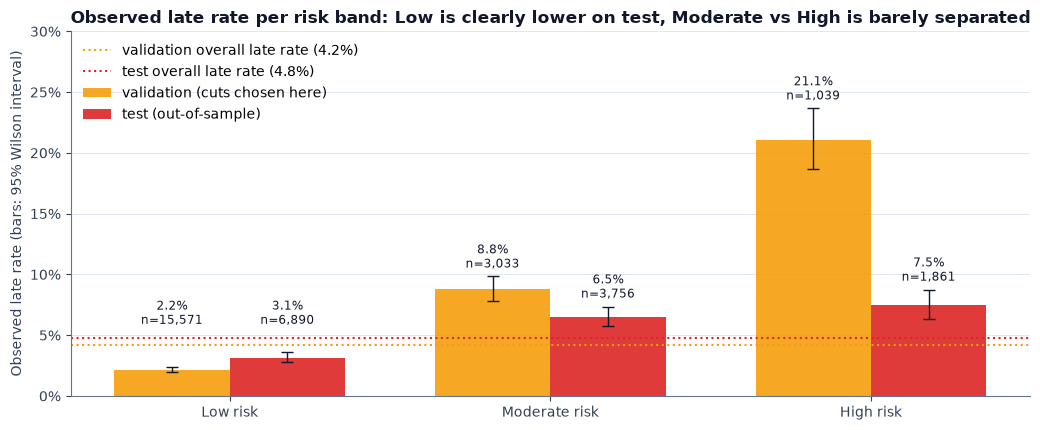

In [25]:
val_bands = tm.band_table(yva, ps_v, bands_th)
test_bands = tm.band_table(yte, ps_t, bands_th)
assert [round(b["late_rate"], 9) for b in val_bands] == [round(b["late_rate"], 9) for b in saved["risk_bands"]["validation"]]
assert [round(b["late_rate"], 9) for b in test_bands] == [round(b["late_rate"], 9) for b in saved["risk_bands"]["test"]]
vd, td = tm.band_diagnostics(val_bands), tm.band_diagnostics(test_bands)

rows = []
for v, t_ in zip(val_bands, test_bands):
    rows.append({"band": v["band"],
                 "validation n": v["n"], "validation share": vd["shares"][v["band"]], "validation late n": v["n_late"], "validation late rate": v["late_rate"],
                 "validation 95% interval": f"{pct(v['late_ci_low'], 1)} - {pct(v['late_ci_high'], 1)}",
                 "test n": t_["n"], "test share": td["shares"][t_["band"]], "test late n": t_["n_late"], "test late rate": t_["late_rate"],
                 "test 95% interval": f"{pct(t_['late_ci_low'], 1)} - {pct(t_['late_ci_high'], 1)}"})
band_df = pd.DataFrame(rows).set_index("band")
display(band_df)
print("Validation:", vd["note"]); print("Test      :", td["note"])

for b in test_bands:
    key = b["band"].lower()
    QUOTED[f"tb_{key}_n"] = f"{b['n']:,}"
    QUOTED[f"tb_{key}_rate"] = pct(b["late_rate"], 1)
    QUOTED[f"tb_{key}_ci"] = f"{pct(b['late_ci_low'], 1)} - {pct(b['late_ci_high'], 1)}"
    QUOTED[f"tb_{key}_share"] = pct(td["shares"][b["band"]], 1)
for b in val_bands:
    key = b["band"].lower()
    QUOTED[f"vb_{key}_rate"] = pct(b["late_rate"], 1)
    QUOTED[f"vb_{key}_share"] = pct(vd["shares"][b["band"]], 1)
QUOTED["cut_moderate"] = f"{bands_th['moderate']:.3f}"
QUOTED["cut_high"] = f"{bands_th['high']:.3f}"
QUOTED["f1_threshold"] = f"{th:.3f}"

fig, ax = plt.subplots(figsize=(10.5, 4.4))
w = 0.36
x = np.arange(3)
for off, bands, lab, col in ((-w / 2, val_bands, "validation (cuts chosen here)", P["amber"]), (w / 2, test_bands, "test (out-of-sample)", P["red"])):
    r_ = np.array([b["late_rate"] for b in bands]); lo_ = np.array([b["late_ci_low"] for b in bands]); hi_ = np.array([b["late_ci_high"] for b in bands])
    bars = ax.bar(x + off, r_, w, color=col, alpha=0.9, label=lab, yerr=[r_ - lo_, hi_ - r_], capsize=4, error_kw={"ecolor": P["navy"], "lw": 1})
    for b_, bd, rr, hh in zip(bars, bands, r_, hi_):
        ax.text(b_.get_x() + b_.get_width() / 2, max(hh, 0.052) + 0.004, f"{rr:.1%}\nn={bd['n']:,}", ha="center", va="bottom", fontsize=8.5, color=P["navy"])
ax.axhline(yva.mean(), color=P["amber"], ls=":", lw=1.5, label=f"validation overall late rate ({yva.mean():.1%})")
ax.axhline(yte.mean(), color=P["red"], ls=":", lw=1.5, label=f"test overall late rate ({yte.mean():.1%})")
ax.set_xticks(x, ["Low risk", "Moderate risk", "High risk"]); ax.set_ylim(0, 0.30)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_ylabel("Observed late rate (bars: 95% Wilson interval)")
ax.set_title("Observed late rate per risk band: Low is clearly lower on test, Moderate vs High is barely separated")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
save_show(fig, "37_risk_bands_validation_vs_test")

In [26]:
# Does the pooled band picture hide a group effect?  Same-state vs other-state orders on the TEST window (descriptive).
bd = tm.same_state_breakdown(yte, ps_t, te["same_state"].to_numpy(), bands_th)
rows = []
for g, lab in (("same_state", "same-state (seller and customer in one state)"), ("other_state", "other-state")):
    for band in ("Low", "Moderate", "High"):
        c_ = bd[g]["bands"][band]
        rows.append({"group": lab, "band": band, "n": c_["n"], "late n": c_["n_late"], "observed late rate": c_["late_rate"],
                     "95% interval": f"{pct(c_['late_ci_low'], 1)} - {pct(c_['late_ci_high'], 1)}"})
display(pd.DataFrame(rows).set_index(["group", "band"]))
for g in ("same_state", "other_state"):
    print(f"{g:<12}: n={bd[g]['n']:,}  observed late rate {pct(bd[g]['observed_late_rate'], 1)}  vs mean predicted {pct(bd[g]['mean_predicted'], 1)}")
assert bd == saved["risk_bands"]["test_by_same_state"] or abs(bd["same_state"]["observed_late_rate"] - saved["risk_bands"]["test_by_same_state"]["same_state"]["observed_late_rate"]) < 1e-9
QUOTED["ss_n"] = f"{bd['same_state']['n']:,}"
QUOTED["ss_obs"] = pct(bd["same_state"]["observed_late_rate"], 1)
QUOTED["ss_pred"] = pct(bd["same_state"]["mean_predicted"], 1)
QUOTED["os_n"] = f"{bd['other_state']['n']:,}"
QUOTED["os_obs"] = pct(bd["other_state"]["observed_late_rate"], 1)
QUOTED["os_pred"] = pct(bd["other_state"]["mean_predicted"], 1)

n  late n  observed late rate   95% interval
group                                         band                                                     
same-state (seller and customer in one state) Low       3964     187              0.0472    4.1% - 5.4%
                                              Moderate  1118     179              0.1601  14.0% - 18.3%
                                              High        83      17              0.2048  13.2% - 30.4%
other-state                                   Low       2926      30              0.0103    0.7% - 1.5%
                                              Moderate  2638      66              0.0250    2.0% - 3.2%
                                              High      1778     122              0.0686    5.8% - 8.1%

same_state  : n=5,165  observed late rate 7.4%  vs mean predicted 4.3%
other_state : n=7,342  observed late rate 3.0%  vs mean predicted 9.8%


**Interpretation.**

* The F1-optimal threshold is **0.125**; the Moderate and High band cuts are **0.064** and **0.165**.
* **Validation (cuts chosen here, so in-sample):** Low **2.2%** late (79.3% of orders), Moderate **8.8%** (15.4%), High **21.1%** (5.3%). A clean staircase.
* **Test (out-of-sample):** Low **3.1%** late (95% interval 2.8% - 3.6%, n = 6,890, 55.1% of orders), Moderate **6.5%** (5.8% - 7.4%, n = 3,756, 30.0%), High **7.5%** (6.4% - 8.8%, n = 1,861, 14.9%).
  The order is still monotone and **Low is clearly lower**, but **Moderate and High are barely separated: their intervals overlap**. The High band is only about 1.5× the overall test late rate, not the 5× of validation.
  Also the bands are no longer sized as designed: 14.9% of test orders fall in High (5.3% on validation) because predicted risk is higher on average in the test window (mean predicted risk 7.5% against 4.2% on validation).
* **A pooled band rate hides a group effect.** Among test orders in the Moderate band, same-state orders were late far more often than other-state orders (see the table above). Overall, same-state orders (**n = 5,165**) were late **7.4%** of the time while the model predicted **4.3%**;
  other-state orders (**n = 7,342**) were late **3.0%** while it predicted **9.8%**. The model learned on the training window that same-state delivery is *less* late-prone; in the test window that association reversed (section 3).
* **Practical reading:** "Low" is a reasonable "probably fine" label; "Moderate" and "High" should be read together as "elevated relative to Low", not as two distinct levels of confidence, and the quoted probabilities are rough.

## 8. What the model relies on: permutation importance and coefficients

**Permutation importance** shuffles one *original* column (before the one-hot expansion) in the evaluation window and records how much the PR-AUC of the final model (calibrator included) drops. It is computed on validation (where it can
guide understanding) and on test (diagnostic only; nothing is chosen from it), each with 10 repeats. **These are predictive associations in this model, not causes**: a delayed delivery is not "caused" by `estimated_delivery_days`;
the promise is a proxy for route and distance, for the promise policy that was in force, and for whatever else correlates with it.

permutation importance done in 9s


,validation,validation_sd,test,test_sd
estimated_delivery_days,0.0703,0.0022,0.0288,0.0007
customer_state,0.0579,0.0035,0.0039,0.0018
same_state,0.0504,0.0025,-0.0194,0.0024
seller_state,0.0204,0.0021,0.0107,0.0014
total_volume_cm3,0.0126,0.0012,0.0019,0.0005
total_freight,0.0096,0.0024,-0.0012,0.0010
product_category,0.0083,0.0019,0.0008,0.0017
max_product_height_cm,0.0076,0.0013,0.0011,0.0011
max_product_length_cm,0.0062,0.0010,-0.0001,0.0008
n_items,0.0059,0.0008,0.0013,0.0006


Identical to the permutation importances stored in model_metrics.json: True
Features whose importance changes sign between validation and test: total_freight, freight_ratio, total_weight_g, max_product_length_cm, purchase_dow, same_state
  ... of which more than 2 SD from zero on both windows: freight_ratio, purchase_dow, same_state
  ... of which also larger than 0.01 PR-AUC on test: same_state


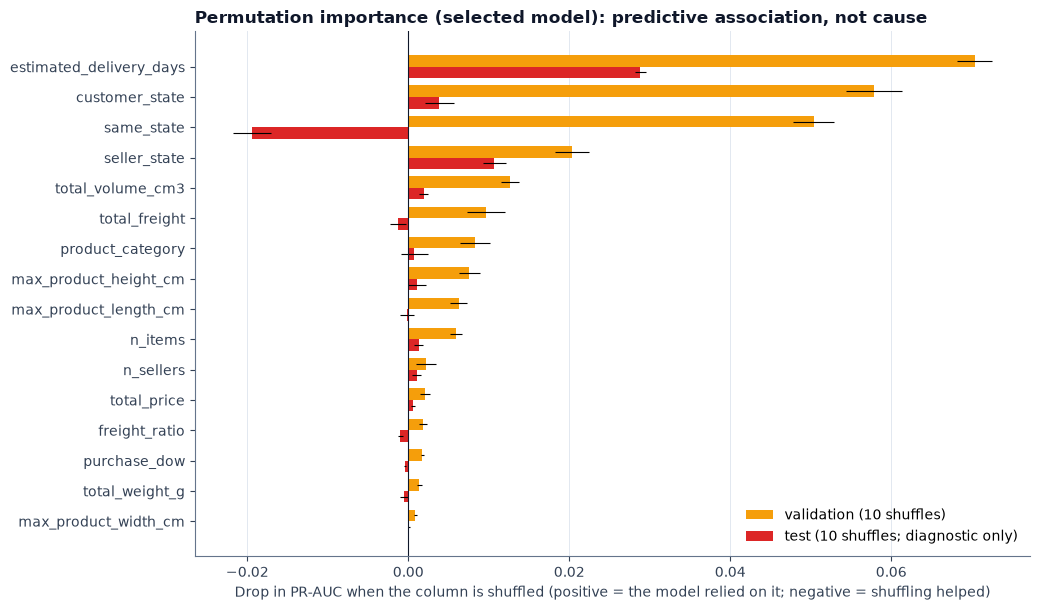

In [27]:
t = time.time()
est_sel = fitted[sel]["calibration"]["estimator"]
pi_v = permutation_importance(est_sel, va[cols], yva, scoring="average_precision", n_repeats=10, random_state=config.RANDOM_STATE, n_jobs=1)
pi_t = permutation_importance(est_sel, te[cols], yte, scoring="average_precision", n_repeats=10, random_state=config.RANDOM_STATE, n_jobs=1)
imp_df = pd.DataFrame({"validation": pi_v.importances_mean, "validation_sd": pi_v.importances_std,
                       "test": pi_t.importances_mean, "test_sd": pi_t.importances_std}, index=cols).sort_values("validation", ascending=False)
print(f"permutation importance done in {time.time() - t:.0f}s")
display(imp_df)
sv = {i["feature"]: i["importance_mean"] for i in saved["permutation_importance"]["items"]}
st_ = {i["feature"]: i["importance_mean"] for i in saved["permutation_importance"]["test_items"]}
assert max(abs(imp_df.loc[f, "validation"] - sv[f]) for f in cols) < 1e-9 and max(abs(imp_df.loc[f, "test"] - st_[f]) for f in cols) < 1e-9
print("Identical to the permutation importances stored in model_metrics.json: True")
flips = [f for f in cols if np.sign(imp_df.loc[f, "validation"]) != np.sign(imp_df.loc[f, "test"])]
print("Features whose importance changes sign between validation and test:", ", ".join(flips))
# Many of those flips are noise around zero.  A flip counts as CLEAR only if the importance is more than 2 SD (of the 10 shuffles)
# away from zero on BOTH windows, in opposite directions.
clear_flips = [f for f in flips if abs(imp_df.loc[f, "validation"]) > 2 * imp_df.loc[f, "validation_sd"] and abs(imp_df.loc[f, "test"]) > 2 * imp_df.loc[f, "test_sd"]]
big_flips = [f for f in clear_flips if abs(imp_df.loc[f, "test"]) > 0.01]
print("  ... of which more than 2 SD from zero on both windows:", ", ".join(clear_flips) or "none")
print("  ... of which also larger than 0.01 PR-AUC on test:", ", ".join(big_flips) or "none")

order = imp_df.index[::-1]
fig, ax = plt.subplots(figsize=(10.5, 6.2))
yy = np.arange(len(order)); h = 0.38
ax.barh(yy + h / 2, imp_df.loc[order, "validation"], h, xerr=imp_df.loc[order, "validation_sd"], color=P["amber"], label="validation (10 shuffles)", error_kw={"lw": 0.8})
ax.barh(yy - h / 2, imp_df.loc[order, "test"], h, xerr=imp_df.loc[order, "test_sd"], color=P["red"], label="test (10 shuffles; diagnostic only)", error_kw={"lw": 0.8})
ax.axvline(0, color=P["navy"], lw=0.8)
ax.set_yticks(yy, order); ax.set_xlabel("Drop in PR-AUC when the column is shuffled (positive = the model relied on it; negative = shuffling helped)")
ax.set_title("Permutation importance (selected model): predictive association, not cause")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
save_show(fig, "38_permutation_importance")

top_v, top_t = imp_df["validation"].idxmax(), imp_df["test"].idxmax()
QUOTED["pi_top_val"] = f"{top_v} ({imp_df.loc[top_v, 'validation']:.3f})"
QUOTED["pi_top_test"] = f"{top_t} ({imp_df.loc[top_t, 'test']:.3f})"
QUOTED["pi_same_val"] = f"{imp_df.loc['same_state', 'validation']:+.3f}"
QUOTED["pi_same_test"] = f"{imp_df.loc['same_state', 'test']:+.3f}"
QUOTED["pi_cust_val"] = f"{imp_df.loc['customer_state', 'validation']:.3f}"
QUOTED["pi_seller_test"] = f"{imp_df.loc['seller_state', 'test']:.3f}"
QUOTED["pi_n_flips"] = f"{len(flips)} of {len(cols)} features"
QUOTED["pi_n_clear"] = f"{len(clear_flips)} of those {len(flips)}"
QUOTED["pi_big_flips"] = ", ".join(f"`{f}`" for f in big_flips)

In [28]:
# Coefficients of the (uncalibrated) logistic regression.  Numeric columns are standardised (coefficient = change in log-odds of
# "late" per +1 SD).  Every one-hot level has its own column (no dropped reference level) and the L2 penalty pulls the levels of one
# feature towards each other, so only DIFFERENCES between levels of the same feature are interpretable (e.g. same_state_1 vs same_state_0).
lr_model = fitted[sel]["base"].named_steps["model"]
nm = fitted[sel]["base"].named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({"column": nm, "coefficient (log-odds)": lr_model.coef_[0]})
coef["odds ratio"] = np.exp(coef["coefficient (log-odds)"])
# number of TRAIN orders at each one-hot level (column sums of the 0/1 design matrix), to show how thinly supported the extreme levels are
Xc = fitted[sel]["base"].named_steps["prep"].transform(fitted[sel]["base"].named_steps["coerce"].transform(tr[cols]))
coef["n train orders at level"] = np.where(coef["column"].str.startswith("cat__"), np.asarray(Xc.sum(axis=0)).ravel().round(), np.nan)
coef["n train orders at level"] = coef["n train orders at level"].astype("Int64")
coef = coef.sort_values("coefficient (log-odds)")
print(f"{len(coef)} coefficients; intercept {lr_model.intercept_[0]:.3f}")
display(pd.concat([coef.head(8).assign(side="lowest (lower late odds)"), coef.tail(8).iloc[::-1].assign(side="highest (higher late odds)")]).set_index("side"))
ssc = coef[coef["column"].str.contains("same_state")]
display(ssc)
c1 = float(coef.loc[coef["column"] == "cat__same_state_1", "coefficient (log-odds)"].iloc[0])
c0 = float(coef.loc[coef["column"] == "cat__same_state_0", "coefficient (log-odds)"].iloc[0])
print(f"same_state: level 1 minus level 0 = {c1 - c0:+.3f} log-odds  ->  odds ratio {np.exp(c1 - c0):.2f} (same-state vs other-state, all else equal, learned on the TRAIN window)")
QUOTED["same_state_or"] = f"{np.exp(c1 - c0):.2f}"
lo_row, hi_row = coef.iloc[0], coef.iloc[-1]
QUOTED["coef_lowest"] = f"`{lo_row['column'].replace('cat__', '')}` ({lo_row['coefficient (log-odds)']:+.2f})"
QUOTED["coef_highest"] = f"`{hi_row['column'].replace('cat__', '')}` ({hi_row['coefficient (log-odds)']:+.2f}, {int(hi_row['n train orders at level']):,} train orders)"
ext = pd.concat([coef.head(8), coef.tail(8)])
QUOTED["coef_ext_kinds"] = f"{ext['column'].str.replace('cat__', '').str.extract(r'^(customer_state|seller_state|product_category|same_state)')[0].nunique()} different features"

114 coefficients; intercept -1.836


,column,coefficient (log-odds),odds ratio,n train orders at level
side,,,,
lowest (lower late odds),cat__same_state_1,-1.2924,0.2746,21697
lowest (lower late odds),cat__customer_state_PR,-1.0547,0.3483,3267
lowest (lower late odds),cat__customer_state_MG,-1.0167,0.3618,7732
lowest (lower late odds),cat__customer_state_DF,-0.8064,0.4465,1333
lowest (lower late odds),cat__product_category_home_appliances,-0.7877,0.4549,375
lowest (lower late odds),cat__customer_state_SP,-0.7770,0.4598,25648
lowest (lower late odds),cat__product_category_luggage_accessories,-0.6185,0.5388,767
lowest (lower late odds),cat__product_category_market_place,-0.6159,0.5401,216
highest (higher late odds),cat__seller_state_MA,1.3541,3.8734,61


,column,coefficient (log-odds),odds ratio,n train orders at level
113,cat__same_state_1,-1.2924,0.2746,21697
112,cat__same_state_0,-0.2659,0.7665,42356


same_state: level 1 minus level 0 = -1.027 log-odds  ->  odds ratio 0.36 (same-state vs other-state, all else equal, learned on the TRAIN window)


**Interpretation.**

* **`estimated_delivery_days`** is the most important column on both windows (**estimated_delivery_days (0.070)** on validation, **estimated_delivery_days (0.029)** on test). It is a purchase-time promise, so it is legitimate, but as noted above its range shifted in the test window.
* **Geography** (`customer_state`, `same_state`, `seller_state`) carries most of the rest on validation (customer_state **0.058**, same_state **+0.050**), but on test the picture changes: `same_state` becomes **-0.019**
  (shuffling it *helps*, because the learned association has reversed), `customer_state` falls to 0.004 and `seller_state` (**0.011**) is the second-most useful column.
* **The ranking does not transfer cleanly.** **6 of 16 features** change sign between validation and test, but several of those are noise around zero (their test importance is within about 2 SD of zero). **3 of those 6** are more than 2 SD from zero on both windows; only **`same_state`** is a large reversal (> 0.01 PR-AUC on test). The other small validation importances (freight, weight, dimensions) are close to zero on test.
  Treat the validation ranking as a description of what the model fitted the earlier regime with, not as a stable list of drivers.
* **Coefficients.** In the logistic regression, same-state orders have an odds ratio of **0.36** against other-state orders (all else equal) *on the training window*; the single lowest coefficient is `same_state_1` (-1.29) and the single highest is `seller_state_MA` (+1.35, 61 train orders). The eight lowest and eight highest coefficients mix levels of **4 different features** (same-state flag, customer state, seller state, product category), many of the highest ones resting on a few hundred train orders or fewer (see the table's order counts), so they are **not** read as a ranking of places or product types.
  One-hot coefficients are only meaningful as differences between levels of the same feature (see the cell comment). These are descriptive of the fitted model, not causal claims.

## 9. Final model selection and the distribution-shift diagnosis

**Selection rule (the intended protocol; it uses validation scores only):** rank candidates by **validation PR-AUC** of their uncalibrated scores, then prefer the **simplest** model whose score is within one paired-bootstrap standard deviation of the best.
This avoids paying complexity for differences that are within noise.

After the decision, the diagnostics below ask *why* the selected model is so much weaker on test than on validation.

In [29]:
t = time.time()
contenders = [n_ for n_ in fitted if n_ != "dummy_prior"]
val_pr = {n_: float(average_precision_score(yva, val_base[n_])) for n_ in fitted}
boot_va = tm.bootstrap_scores(yva, val_base, 300, config.RANDOM_STATE)
best, within, chosen = tm.choose_model(val_pr, {n_: boot_va[n_]["pr_auc"] for n_ in contenders})
rows = []
for n_ in fitted:
    c_ = tm._ci(boot_va[n_]["pr_auc"])
    rows.append({"model": tm.MODEL_LABELS[n_], "validation PR-AUC (uncalibrated)": val_pr[n_], "95% bootstrap interval": f"{c_[0]:.3f} - {c_[1]:.3f}",
                 "simplicity rank (1 = simplest)": tm.SIMPLICITY_RANK.get(n_, "-"), "within noise of the best": n_ in within,
                 "test PR-AUC (looked at AFTER the decision)": met[n_]["test"]["pr_auc"], "test ROC-AUC": met[n_]["test"]["roc_auc"]})
sel_df = pd.DataFrame(rows).set_index("model")
display(sel_df)
print(f"bootstrap done in {time.time() - t:.0f}s")
print(f"\nBest validation PR-AUC: {tm.MODEL_LABELS[best]};  within one paired-bootstrap SD of it: {[tm.MODEL_LABELS[n_] for n_ in within]};  chosen (simplest of those): {tm.MODEL_LABELS[chosen]}")
assert chosen == saved["selected_model"]["name"] == sel
print("Same choice as the saved model:", chosen == saved["selected_model"]["name"])
print()
wrap("Saved rationale: " + saved["selected_model"]["rationale"])
QUOTED["val_pr_lr_unc"] = f"{val_pr['logistic_regression']:.3f}"
QUOTED["val_pr_rf_unc"] = f"{val_pr['random_forest']:.3f}"
QUOTED["val_pr_hgb_unc"] = f"{val_pr['hist_gradient_boosting']:.3f}"
QUOTED["test_pr_lr_unc"] = f"{average_precision_score(yte, test_base['logistic_regression']):.3f}"

,validation PR-AUC (uncalibrated),95% bootstrap interval,simplicity rank (1 = simplest),within noise of the best,test PR-AUC (looked at AFTER the decision),test ROC-AUC
model,,,,,,
Dummy baseline (class prior),0.0417,0.039 - 0.044,-,False,0.0481,0.5000
Logistic regression,0.1385,0.125 - 0.158,1,True,0.0726,0.6174
Random forest,0.1206,0.105 - 0.137,2,False,0.0587,0.5951
Histogram gradient boosting,0.1381,0.120 - 0.159,2,True,0.0505,0.5066


bootstrap done in 7s

Best validation PR-AUC: Logistic regression;  within one paired-bootstrap SD of it: ['Logistic regression', 'Histogram gradient boosting'];  chosen (simplest of those): Logistic regression
Same choice as the saved model: True

Saved rationale: Primary metric: validation PR-AUC (average precision), because only 4.2% of validation orders are
late. Best uncalibrated score: Logistic regression (0.138); models within one paired-bootstrap standard deviation of
it: Logistic regression, Histogram gradient boosting. Logistic regression was chosen as the simplest of those
(uncalibrated validation PR-AUC 0.138, 95% bootstrap interval 0.125-0.158) versus the 0.042 no-skill baseline (=
validation late rate), i.e. a 3.3x lift. isotonic calibration kept (fitted on validation). Mean predicted risk vs
observed late rate: validation 4.2% vs 4.2%; test 7.5% vs 4.8%. Test window (untouched until the end; n=12,507, 4.8%
late): ROC-AUC 0.617 (validation 0.781); PR-AUC 0.073 vs no-skill

,n,observed late rate,mean predicted risk,ROC-AUC,PR-AUC,lift (PR-AUC / late rate),Brier,Brier of constant (train prior)
window,,,,,,,,
train (in-sample),64053,0.0798,0.0456,0.7076,0.1752,2.1958,0.0710,0.0734
validation (tuned),19643,0.0417,0.0418,0.7813,0.1403,3.3609,0.0376,0.0414
test (out-of-sample),12507,0.0481,0.0749,0.6174,0.0726,1.5113,0.0487,0.0468


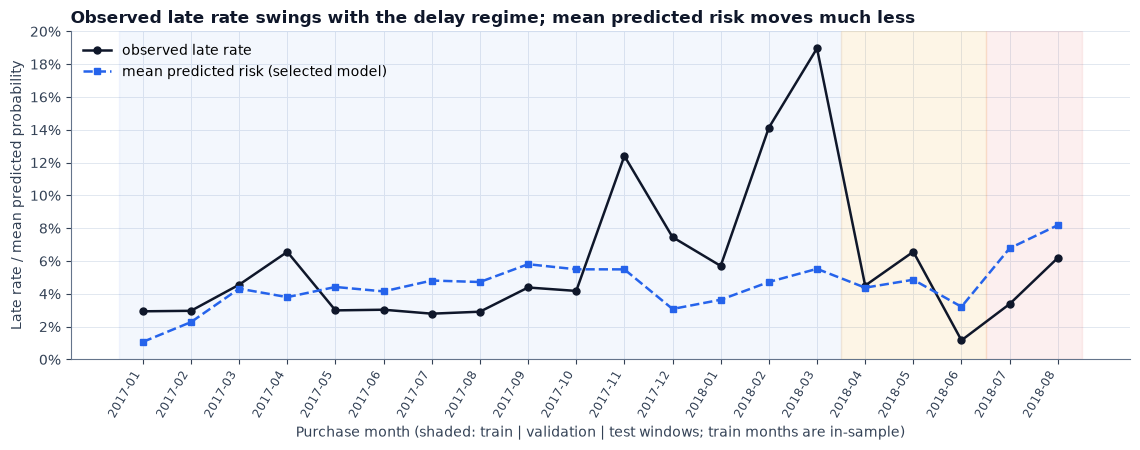

Correlation of monthly observed vs monthly mean predicted risk inside the training window (n=15 months): 0.38


In [30]:
# How the shift shows up for the selected model: window-level calibration and ranking (train rows are IN-SAMPLE).
def sel_score(frame):
    return tm._proba(est_sel, frame[cols], floors[sel])

p_tr = sel_score(tr)
rows = []
for lab, part, ps in (("train (in-sample)", tr, p_tr), ("validation (tuned)", va, ps_v), ("test (out-of-sample)", te, ps_t)):
    yy_ = part[tm.TARGET].to_numpy()
    rows.append({"window": lab, "n": len(part), "observed late rate": yy_.mean(), "mean predicted risk": ps.mean(),
                 "ROC-AUC": roc_auc_score(yy_, ps), "PR-AUC": average_precision_score(yy_, ps),
                 "lift (PR-AUC / late rate)": average_precision_score(yy_, ps) / yy_.mean(), "Brier": float(np.mean((ps - yy_) ** 2)),
                 "Brier of constant (train prior)": float(np.mean((tr[tm.TARGET].mean() - yy_) ** 2))})
shift_df = pd.DataFrame(rows).set_index("window")
display(shift_df)
QUOTED["train_insample_auc"] = f"{shift_df.iloc[0]['ROC-AUC']:.3f}"
QUOTED["test_meanpred"] = pct(shift_df.loc["test (out-of-sample)", "mean predicted risk"], 1)
QUOTED["val_meanpred"] = pct(shift_df.loc["validation (tuned)", "mean predicted risk"], 1)
QUOTED["test_brier_const"] = f"{shift_df.loc['test (out-of-sample)', 'Brier of constant (train prior)']:.4f}"
QUOTED["test_lift"] = f"{shift_df.loc['test (out-of-sample)', 'lift (PR-AUC / late rate)']:.1f}"
QUOTED["val_lift"] = f"{shift_df.loc['validation (tuned)', 'lift (PR-AUC / late rate)']:.1f}"

# monthly observed vs predicted
allm = pd.concat([tr.assign(_p=p_tr), va.assign(_p=ps_v), te.assign(_p=ps_t)])
mm = (allm.assign(month=allm["order_purchase_timestamp"].dt.strftime("%Y-%m")).groupby("month")
      .agg(n=(tm.TARGET, "size"), observed=(tm.TARGET, "mean"), predicted=("_p", "mean")).reset_index())
mm["window"] = mm["month"].map(window_of)
fig, ax = plt.subplots(figsize=(11.5, 4.6))
pp = np.arange(len(mm))
ax.axvspan(-0.5, b1, color=P["blue"], alpha=0.05); ax.axvspan(b1, b2, color=P["amber"], alpha=0.10); ax.axvspan(b2, pp[-1] + 0.5, color=P["red"], alpha=0.07)
ax.plot(pp, mm["observed"], color=P["navy"], marker="o", ms=5, lw=1.8, label="observed late rate")
ax.plot(pp, mm["predicted"], color=P["blue"], marker="s", ms=4.5, lw=1.8, ls="--", label="mean predicted risk (selected model)")
ax.set_xticks(pp, mm["month"], rotation=60, ha="right", fontsize=8.5)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_ylabel("Late rate / mean predicted probability")
ax.set_xlabel("Purchase month (shaded: train | validation | test windows; train months are in-sample)")
ax.set_title("Observed late rate swings with the delay regime; mean predicted risk moves much less")
ax.set_yticks(np.arange(0, 0.21, 0.02))
ax.legend(loc="upper left")
save_show(fig, "39_observed_vs_predicted_monthly")
corr_train = float(np.corrcoef(mm.loc[mm["window"] == "train", "observed"], mm.loc[mm["window"] == "train", "predicted"])[0, 1])
print(f"Correlation of monthly observed vs monthly mean predicted risk inside the training window (n={int((mm['window'] == 'train').sum())} months): {corr_train:.2f}")
QUOTED["corr_train_months"] = f"{corr_train:.2f}"
mar = mm.loc[mm["month"] == "2018-03"].iloc[0]
QUOTED["mar18_obs"] = pct(mar["observed"], 1)
QUOTED["mar18_pred"] = pct(mar["predicted"], 1)

In [31]:
# Test window split by whether the order's promise/size lies inside the TRAINING range (extrapolation vs interpolation).
tr_num = tr[numeric].astype("float64")
lo_, hi_ = tr_num.min(), tr_num.max()
te_num = te[numeric].astype("float64")
outside = ((te_num < lo_) | (te_num > hi_)).any(axis=1).to_numpy()
rows = []
for lab, m in (("inside the training feature range", ~outside), ("outside the training range (mostly shorter promises)", outside)):
    yy_ = yte[m]
    ok = len(np.unique(yy_)) == 2
    rows.append({"test orders": lab, "n": int(m.sum()), "n late": int(yy_.sum()), "observed late rate": yy_.mean(),
                 "mean predicted": ps_t[m].mean(), "ROC-AUC": roc_auc_score(yy_, ps_t[m]) if ok else np.nan,
                 "small sample (n < 100)?": int(m.sum()) < config.DEFAULT_MIN_ORDERS})
sup = pd.DataFrame(rows).set_index("test orders")
display(sup)
print(f"estimated_delivery_days: training range {lo_['estimated_delivery_days']:.0f}-{hi_['estimated_delivery_days']:.0f} days; "
      f"share of test orders below the training minimum: {(te_num['estimated_delivery_days'] < lo_['estimated_delivery_days']).mean():.1%}")
QUOTED["sup_in_auc"] = f"{sup.iloc[0]['ROC-AUC']:.3f}"
QUOTED["sup_out_auc"] = f"{sup.iloc[1]['ROC-AUC']:.3f}"
QUOTED["sup_out_meanpred"] = pct(sup.iloc[1]["mean predicted"], 1)
QUOTED["sup_out_obs"] = pct(sup.iloc[1]["observed late rate"], 1)
QUOTED["sup_in_obs"] = pct(sup.iloc[0]["observed late rate"], 1)
QUOTED["promise_min_train"] = f"{lo_['estimated_delivery_days']:.0f} to {hi_['estimated_delivery_days']:.0f} days"

,n,n late,observed late rate,mean predicted,ROC-AUC,small sample (n < 100)?
test orders,,,,,,
inside the training feature range,11244,388,0.0345,0.0749,0.6185,False
outside the training range (mostly shorter promises),1263,213,0.1686,0.0751,0.5511,False


estimated_delivery_days: training range 8-156 days; share of test orders below the training minimum: 10.1%


**Interpretation — selection.**

* Validation PR-AUC (uncalibrated): logistic regression **0.138**, histogram gradient boosting **0.138**, random forest **0.121**. Logistic regression and boosting are within bootstrap noise of each other, so the **simpler model, logistic regression, is selected**.
  The choice was made before test results were looked at, and the later test results (PR-AUC **0.079** uncalibrated, 0.073 deployed, versus 0.059 and 0.050 for the others) are consistent with it, but they are not the reason for the choice.
* **Why simplicity matters here:** the flexible models gain nothing on validation and lose more on test; a transparent model with a handful of strong effects is easier to audit and explain.

**Interpretation — why test is weaker than validation (descriptive diagnostics; causes are not identifiable from this data).**

* **Not over-fitting in the usual sense.** The in-sample training ROC-AUC is only **0.708**; validation is higher (**0.781**) than training, and test is lowest (**0.617**). The model is not memorising noise; the *task* differs across windows.
* **Base-rate shift and miscalibration.** The mean predicted risk is **4.2%** on validation but **7.5%** on test, while observed late rates are 4.2% and 4.8%. The Brier score of the constant baseline on test is **0.0468** (the model: 0.0487). Lift over no skill falls from **3.4** (validation) to **1.5** (test).
* **Extrapolation.** The training range of `estimated_delivery_days` is **8 to 156 days**; in the test window 10.1% of orders have a shorter promise. On that subgroup the observed late rate is **16.9%** (against 3.5% for in-range orders) yet the mean predicted risk is **7.5%**. One plausible reason is that the model never saw promises this short in training and so cannot extrapolate to them; this notebook does not test that explanation.
  Its ROC-AUC is **0.551** there versus **0.618** on in-range orders.
* **Spikes are invisible to a purchase-time model.** Over the 15 training months the correlation between the observed monthly late rate and the model's mean predicted risk is only **0.38**; in March 2018 the late rate was **19.0%** while the mean predicted risk was **5.5%** (the model's
  mean prediction moves far less than the observed rate). Delay episodes like Nov 2017 and Feb–Mar 2018 are consistent with conditions that the purchase-time order record does not contain, but the data cannot show what those conditions were.

## 10. How the saved bundle is used by the app

`python -m src.train_model` writes **one** file that the app needs for prediction, `models/delay_classifier.joblib`: a dictionary holding the fitted pipeline (preprocessing + estimator + calibrator), the feature lists,
the decision threshold, the risk-band cuts, form options (valid states and categories, training ranges) and the test-window caveat. `prediction.load_model()` loads it (cached by the app), `prediction.predict_risk(inputs)` validates a raw
purchase-time input, derives the model features with the **same** function used in training, scores it and returns the probability, the band and plain-language caveats.

The cells below (1) verify that the bundle reproduces this notebook's scores exactly, (2) score **three real orders from the test window** — one drawn at random with a fixed seed from each risk band — and show what actually happened,
and (3) mimic the app's form with only the required fields. **The three orders are an illustration of the interface, not evidence of accuracy.**

In [32]:
bundle = pred.load_model()
print("Bundle keys:", ", ".join(sorted(bundle)))
print(f"\nmodel_name={bundle['model_name']} | calibrated={bundle['calibrated']} | decision_threshold={bundle['decision_threshold']:.4f} | "
      f"risk_thresholds={ {k: round(v, 4) for k, v in bundle['risk_thresholds'].items()} } | trained with scikit-learn {bundle['sklearn_version']}")
print("train window:", bundle["train_window"])

# 1. The bundle is the notebook's model: same scores on every test order (after the same exact-zero floor).
bundle_scores = pred._score(bundle["pipeline"], te, bundle["feature_columns"], float(bundle["probability_floor"]))
bundle_dev = float(np.max(np.abs(bundle_scores - ps_t)))
print(f"\nmax |bundle score - notebook score| over {len(te):,} test orders: {bundle_dev:.2e}")
assert bundle_dev < 1e-9

Bundle keys: base_pipeline, calibrated, categorical_features, decision_threshold, feature_columns, form_options, metrics_summary, model_name, numeric_features, pipeline, probability_floor, risk_thresholds, score_resolution, sklearn_version, target, test_window_caveat, train_window, trained_at

model_name=logistic_regression | calibrated=True | decision_threshold=0.1250 | risk_thresholds={'moderate': 0.0643, 'high': 0.1651} | trained with scikit-learn 1.9.1
train window: {'start': '2017-01-05', 'end': '2018-03-31', 'n': 64053}

max |bundle score - notebook score| over 12,507 test orders: 0.00e+00


In [33]:
# 2. predict_risk on three REAL orders from the TEST window, one drawn at random (fixed seed) from each risk band of the
#    deployed model, then compared with what actually happened.  Illustration only - three orders prove nothing.
rng = np.random.default_rng(config.RANDOM_STATE)
band_of = np.where(ps_t >= bands_th["high"], "High", np.where(ps_t >= bands_th["moderate"], "Moderate", "Low"))
picked = [int(rng.choice(np.flatnonzero(band_of == b))) for b in ("Low", "Moderate", "High")]
fields = ["customer_state", "seller_state", "product_category", "n_items", "total_price", "total_freight", "n_sellers",
          "total_weight_g", "total_volume_cm3", "max_product_length_cm", "max_product_height_cm", "max_product_width_cm", "estimated_delivery_days"]
rows, notes_ = [], []
for i in picked:
    r = te.iloc[i]
    inputs = {f: (None if pd.isna(r[f]) else (r[f].item() if hasattr(r[f], "item") else r[f])) for f in fields}
    inputs["purchase_date"] = r["order_purchase_timestamp"].strftime("%Y-%m-%d")
    out = pred.predict_risk(inputs, bundle)
    assert abs(out["probability"] - ps_t[i]) < 1e-9
    rows.append({"order_id": r["order_id"][:8] + "...", "route": f"{r['seller_state']} -> {r['customer_state']}", "category": r["product_category"],
                 "promised days": int(r["estimated_delivery_days"]), "items": int(r["n_items"]), "freight / price": f"{r['total_freight']:.0f} / {r['total_price']:.0f}",
                 "predicted late probability": out["probability"], "risk band": out["risk_label"],
                 "ACTUAL outcome": f"{'LATE' if r[tm.TARGET] == 1 else 'on time'} ({int(r['delivery_delay_days']):+d} days vs promise)"})
    notes_.append((out["risk_label"], out["probability_note"], out["warnings"]))
    QUOTED[f"demo_p_{out['risk_label'].lower()}"] = f"{out['probability']:.3f}"
    QUOTED[f"demo_outcome_{out['risk_label'].lower()}"] = f"{int(r['delivery_delay_days']):+d} days"
demo = pd.DataFrame(rows)
display(demo)
print("predict_risk(...) equals the notebook score for all three orders: True\n")
for lab, note, warn in notes_:
    print(f"[{lab} band example] non-blocking input warnings: {warn if warn else 'none'}")
print("\nThe probability note that accompanies every prediction (identical text for the three, apart from the band-specific sentence):")
wrap(notes_[0][1])

,order_id,route,category,promised days,items,freight / price,predicted late probability,risk band,ACTUAL outcome
0,8993af9c...,SP -> SP,baby,22,1,18 / 150,0.0189,Low,on time (-14 days vs promise)
1,33b4b136...,SP -> SP,auto,6,1,9 / 250,0.0643,Moderate,on time (-4 days vs promise)
2,6df06dce...,SC -> MG,housewares,16,1,212 / 649,0.2145,High,on time (-10 days vs promise)


predict_risk(...) equals the notebook score for all three orders: True

[Low band example] non-blocking input warnings: ['purchase_date is outside the dates the model was trained on (2017-01-05 to 2018-03-31, its fitting window); it only learned the day-of-week pattern seen in that period.']
[Moderate band example] non-blocking input warnings: ['estimated_delivery_days = 6 is outside the range the model was trained on (8 to 156): the model is extrapolating, so treat this estimate with extra caution.', 'purchase_date is outside the dates the model was trained on (2017-01-05 to 2018-03-31, its fitting window); it only learned the day-of-week pattern seen in that period.']
[High band example] non-blocking input warnings: ['purchase_date is outside the dates the model was trained on (2017-01-05 to 2018-03-31, its fitting window); it only learned the day-of-week pattern seen in that period.']

The probability note that accompanies every prediction (identical text for the three, apart from t

In [34]:
# 3. What the app's form does: only the required fields are given, the rest is filled from training defaults (and reported).
minimal = {"customer_state": "SP", "seller_state": "SP", "product_category": "health_beauty", "n_items": 1,
           "total_price": 90.0, "total_freight": 15.0, "purchase_date": "2018-08-10"}
out = pred.predict_risk(minimal, bundle)
print(f"Minimal input -> probability {out['probability']:.3f}, band {out['risk_label']}, calibrated={out['calibrated']}")
print("Fields filled from training defaults:", ", ".join(out["assumptions_used"]) or "none")
wrap("Probability note: " + str(out["probability_note"]))
try:
    pred.predict_risk({**minimal, "customer_state": "XX"}, bundle)
except ValueError as exc:
    print("\nInvalid input is rejected with a readable message:", exc)

Minimal input -> probability 0.016, band Low, calibrated=True
Fields filled from training defaults: total_weight_g, estimated_delivery_days, n_sellers, total_volume_cm3, max_product_length_cm, max_product_height_cm, max_product_width_cm
Probability note: Calibrated scores take only 30 distinct values (a step function, highest 30.8%), so nearby inputs
often get the same probability; read it as a band, not a precise figure. On the untouched test window (2018-07-01 to
2018-08-29, n=12,507, 4.8% late) the model's mean predicted risk was 7.5% against 4.8% observed, and its Brier score
(0.0487) was not better than a constant base-rate prediction (0.0468), so read the probability as a rough ranking, not
an exact chance. Test orders in the Low band were late 3.1% of the time (n=6,890) (same-state orders 4.7% (n=3,964);
other-state orders 1.0% (n=2,926)). For same-state orders like this one the mean predicted risk was 4.3% against 7.4%
observed (n=5,165). Performance degraded on this later wind

**Interpretation.**

* **Same model, same scores.** The loaded bundle reproduces this notebook's scores for all 12,507 test orders to within 0 (maximum absolute difference printed above), so the app and the notebook use one and the same model.
* **Three real orders, three on-time outcomes.** The orders drawn from the Low, Moderate and High bands had predicted late probabilities of **0.019**, **0.064** and **0.214**, and all three actually arrived early (**-14 days**, **-4 days** and **-10 days** relative to the promise).
  That is *not* a failure of the model and *not* a success either: on the test window even High-band orders were late only 7.5% of the time, so about 92% of them arrive on time. Three orders cannot validate or invalidate a probabilistic model; they only show what the interface returns.
  (The seed is fixed and the three orders were not hand-picked.)
* **What the app adds around a prediction.** Each result carries the band, the step-function caveat (the calibrated score takes only 30 distinct values), the test-window finding (mean predicted 7.5% versus 4.8% observed; Brier no better than a constant), and non-blocking warnings.
  Here every test-window order triggers the "purchase date is outside the training period" warning, and the Moderate example (a 6-day promise) also triggers an extrapolation warning, because training promises ranged from 8 days upward.
* **Required inputs only.** With just the seven required fields the form fills the other seven from training defaults and lists them as assumptions; an unknown state is rejected with a readable message rather than scored.

## 11. Conclusions, limitations and what would be needed to improve

### What we can say
1. **Target and protocol.** The target is lateness against the promised calendar date (6.77% of 96,470 delivered orders). Predictors are restricted to purchase-time information (leakage audit passed), the split is chronological, preprocessing is fitted on training data only, and every number
   for the saved model is reproduced in this notebook (exactly for logistic regression; within explained floating-point noise for the random forest).
2. **Selected model.** Logistic regression, chosen on validation PR-AUC as the simplest model within bootstrap noise of the best, calibrated on validation, with an F1-optimal threshold of 0.125 and risk-band cuts of 0.064 and 0.165.
3. **Performance — honestly.** On the untouched test window: ROC-AUC 0.617 (0.599 - 0.637), PR-AUC 0.073 (0.064 - 0.083) versus 0.048 no-skill, precision 7.0%, recall 25.8% at the chosen threshold. On validation the same code gave ROC-AUC 0.781 and PR-AUC 0.140, but validation was used for tuning and is
   **not** an honest estimate. The **Low** band is clearly lower-risk (3.1% late); **Moderate** (6.5%) and **High** (7.5%) are barely separated. The probabilities are not better calibrated than the base rate on test (Brier 0.0487 vs 0.0468).
4. **Why it is weak.** Purchase-time order attributes explain only a small part of the variation in lateness (they predict it only modestly). What the data does show is that the delay regime (months with 12–19% late orders), the promise length and the `same_state` gap all changed between windows, and that 10.1% of test orders had promises outside anything the model had seen. Why these shifted (for example carrier or logistics conditions) cannot be tested with this data.

### Limitations
* **Distribution shift:** late rate 8.0% / 4.2% / 4.8% across windows; the `same_state` association reversed; the promise length changed. Results on future data may differ again in either direction.
* **Short history:** 1.7 years of modelled orders, with a few disruption episodes; no seasonality can be learned, and the test window is only two months (601 late orders, so intervals are wide).
* **Selection bias:** only delivered, labelled orders are modelled; 1.13% of test-window orders were still open and unlabelled.
* **Single split, tuned on one validation window:** the model choice, thresholds and bands rest on a single validation window that is itself unusual (low late rate). A rolling-origin evaluation over several later windows would be more convincing but needs more data than this dataset holds.
* **Historical data ≠ current logistics performance.** These are 2016–2018 Olist orders; nothing here describes today's carriers or today's marketplace.
* **Associations, not causes.** Importance, coefficients and band rates describe how the *model* separates orders. They do not say why orders are late and must not be used to assign blame to states, sellers or categories.

### What would be needed to improve (none of this is in the data used here, and nothing is simulated)
* **Carrier, route and handling data:** which carrier, the actual route, hub transfers, and seller handling time as a *promised* quantity at purchase (for instance the seller's shipping deadline).
* **Real distance:** the Kaggle release of the Olist data also lists a zip-prefix geolocation table that this project does not use; a seller-to-customer distance feature built from it is a natural next experiment. It is **untested here, so no performance claim is made**.
* **External conditions:** weather, strikes and holidays, regional capacity, and the checkout promise policy in force at the time.
* **A longer, more recent history** and **rolling re-training with monitoring**, so that the model is refreshed and its calibration checked whenever the base rate moves.
* **A decision study:** whether flagging the top slice of orders would change an outcome (for instance proactive contact) requires an operational experiment, not a model score.

### How the app presents this
The **Delay Prediction** page shows the model card with these limitations next to every probability, labels bands as ranking aids rather than promises, warns when an input lies outside the training range, and never presents the model as highly accurate.

In [35]:
checks = [
    ("features equal the saved model's feature list", cols == saved["features"]["numeric"] + saved["features"]["categorical"]),
    ("window counts equal the saved split", all(len(parts[k]) == saved["split"][k]["n"] for k in parts)),
    ("dummy, logistic regression and gradient boosting reproduce the saved metrics exactly; the forest within noise", worst < 1e-9 and worst_by_model["random_forest"] < 1e-3),
    ("model choice equals the saved choice", chosen == saved["selected_model"]["name"]),
    ("risk-band cuts equal the saved cuts", bands_th == saved["risk_bands"]["thresholds"]),
    ("saved leakage audit passed", saved["leakage_audit"]["passed"]),
    ("bundle scores equal notebook scores on the test window", bundle_dev < 1e-9),
]
display(pd.DataFrame(checks, columns=["check", "passed"]).set_index("check"))
assert all(ok for _, ok in checks)
print(f"Notebook wall-clock time: {time.time() - T0:.0f}s")
QUOTED["runtime_note"] = "ok"

,passed
check,
features equal the saved model's feature list,True
window counts equal the saved split,True
"dummy, logistic regression and gradient boosting reproduce the saved metrics exactly; the forest within noise",True
model choice equals the saved choice,True
risk-band cuts equal the saved cuts,True
saved leakage audit passed,True
bundle scores equal notebook scores on the test window,True


Notebook wall-clock time: 111s


In [36]:
# Appendix: every number quoted in the Markdown, as computed above (the build script checks the text against this table).
print("###QUOTED###" + json.dumps(QUOTED))
pd.Series(QUOTED, name="value").to_frame()

###QUOTED###{"n_all": "96,470", "n_late_all": "6,534", "late_rate_all": "6.77%", "class_ratio": "13.8", "n_same_day": "1,292", "ts_late_rate": "8.11%", "leak_honest_test_auc": "0.619", "leak_proc_test_auc": "0.807", "leak_proc_test_pr": "0.186", "leak_c2c_test_auc": "0.894", "leak_dur_test_auc": "1.000", "leak_dur_test_pr": "0.994", "leak_dur_val_auc": "1.000", "train_n": "64,053", "train_n_late": "5,110", "train_rate": "8.0%", "validation_n": "19,643", "validation_n_late": "820", "validation_rate": "4.2%", "test_n": "12,507", "test_n_late": "601", "test_rate": "4.8%", "n_before": "267", "gap_train": "-5.1", "promise_train": "24 days", "gap_validation": "-3.1", "promise_validation": "25 days", "gap_test": "+4.4", "promise_test": "17 days", "test_outside_share": "10.1%", "test_outside_n": "1,263", "test_outside_rate": "16.9%", "test_inside_rate": "3.5%", "rand_auc": "0.712", "rand_lift": "2.4", "chron_auc": "0.619", "chron_lift": "1.7", "design_cols": "114 design-matrix columns", "lr_va

,value
n_all,"96,470"
n_late_all,"6,534"
late_rate_all,6.77%
class_ratio,13.8
n_same_day,"1,292"
...,...
demo_p_moderate,0.064
demo_outcome_moderate,-4 days
demo_p_high,0.214
demo_outcome_high,-10 days
